# Youtube: wszystkie wydarzenia razem – czy wydarzenia podwyższają hejt?

Notebook zbiera komentarze z Youtube ze **wszystkich wydarzeń** (`data/interim/youtube/<data>_<wydarzenie>/labeled` + `clean`)
i odpowiada na trzy pytania:

1. **Czy wydarzenia ogólnie podwyższają** `hate`, `hate_migrant` i `migrant` (test łączny dla wszystkich wydarzeń)?
2. **Gdzie zmiana była największa**, a gdzie najmniejsza – i czy zależy od **typu wydarzenia**?
3. **Jakie słowa** dominują w hejcie, czym słownictwo różni się między wydarzeniami i co rośnie po wydarzeniu?

Etykiety i okresy są liczone tak samo jak w notebookach pojedynczych wydarzeń
(`hate_analysis/youtube/<wydarzenie>/`): etykieta = LLM **albo** regex; `przed` = `relative_day < 0`, `po` = `relative_day >= 0`.


In [1]:
import json
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import display
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import confint_proportions_2indep, proportion_confint
from wordcloud import WordCloud

# katalog projektu = pierwszy katalog w górę, który zawiera events.json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "events.json").exists())

# ---- konfiguracja ----
PLATFORM = "youtube"
POST_FROM_DAY = 0       # od którego relative_day liczymy okres "po"
MIN_DAILY_N = 10        # min. liczba komentarzy w dniu, by liczyć dzienny odsetek w testach
TOP_N_WORDS = 20
SEED = 42
ALPHA = 0.05            # poziom istotności
ROLL_DAYS = 7           # okno średniej kroczącej na wykresach czasowych

LABELS = ["hate", "hate_migrant", "migrant"]
LABEL_NAMES = {"hate": "hate (ogólny)", "hate_migrant": "hate wobec migrantów", "migrant": "o migracji",
               "hate_migrant | migrant": "hate wobec migrantów wśród komentarzy o migracji"}
# zestawy etykiet: nazwa -> (kolumna 0/1, kolumna-warunek ograniczająca próbę albo None)
LABEL_SETS = {"hate": ("hate", None), "hate_migrant": ("hate_migrant", None), "migrant": ("migrant", None),
              "hate_migrant | migrant": ("hate_migrant", "migrant")}

# typ i zasięg wydarzeń (klucze = nazwy z events.json)
EVENT_META = {
    "Pakt_Azyl_PE": ("polityka / prawo", "UE / zagranica"),
    "Strategia_Migracyjna": ("polityka / prawo", "Polska"),
    "Smierc_Zolnierza": ("przemoc / incydent", "Polska"),
    "Bojka_Srem": ("przemoc / incydent", "Polska"),
    "Atak_Kamienna_Gora": ("przemoc / incydent", "Polska"),
    "Dezinformacja_Krakow": ("dezinformacja", "Polska"),
    "Ceuta_Masowe_Przekroczenie": ("kryzys graniczny", "UE / zagranica"),
}
TYPE_ORDER = ["polityka / prawo", "przemoc / incydent", "dezinformacja", "kryzys graniczny"]
TYPE_COLORS = {"polityka / prawo": "#2a78d6", "przemoc / incydent": "#eb6834",
               "dezinformacja": "#1baf7a", "kryzys graniczny": "#eda100", "inne": "#8a8984"}
BLUES = LinearSegmentedColormap.from_list("blues", ["#ffffff", "#b7d3f6", "#2a78d6", "#0b3a7a"])

# kolory: kategoryczne sloty w stałej kolejności + neutralne tusze
COLORS = {"komentarze": "#2a78d6", "hate": "#eb6834", "hate_migrant": "#1baf7a", "migrant": "#eda100",
          "przed": "#8a8984", "po": "#2a78d6"}
BAR_BG = "#b7d3f6"
INK, INK2 = "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.figsize": (13, 4.5), "figure.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "lines.linewidth": 2, "legend.frameon": False,
})
pd.set_option("display.max_colwidth", 200)


def fmt_p(t, digits=3):
    t = t.copy()
    for c in t.columns:
        if c == "p" or c.startswith("p "):
            t[c] = t[c].map(lambda v: f"{v:.3g}")
    return t.round(digits)

def type_legend(fig, extra=()):
    """Wspólna legenda typów wydarzeń (kolory) + dodatkowe wpisy (uchwyt, opis)."""
    used = {v[0] for v in EVENT_META.values()}
    items = [(Patch(color=c), t) for t, c in TYPE_COLORS.items() if t in used] + list(extra)
    handles, labels = [h for h, _ in items], [l for _, l in items]
    fig.legend(handles, labels, loc="lower center", ncol=len(handles), bbox_to_anchor=(0.5, -0.04), frameon=False)


## 0. Wczytanie danych

In [2]:
META_COLS = [
    "comment_id",
    "platform",
    "relative_day",
    "created_date",
    "created_at",
    "thread_id",
    "post_id",
    "depth",
    "author_id",
    "likes",
    "ukraine_related",
    "refugee_migrant_related",
    "political",
]
EVENTS = json.loads((ROOT / "events.json").read_text(encoding="utf-8"))


def to_bool(s):
    if s is None:
        return False
    return (
        s.fillna(False)
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(["true", "1", "1.0"])
    )


def load_event(event, platform=PLATFORM, post_from_day=POST_FROM_DAY):
    event_date = pd.Timestamp(EVENTS[event])
    event_dir = (
        ROOT / "data" / "interim" / platform / f"{event_date:%Y-%m-%d}_{event}"
    )

    labeled_file = event_dir / "labeled" / "comments.csv"
    clean_file = event_dir / "clean" / "comments.csv"

    if not clean_file.exists():
        print(f"⚠️ Pominięto {event}: brak pliku czystych komentarzy ({clean_file.name})")
        return None, 0

    all_comments = pd.read_csv(
        clean_file,
        encoding="utf-8-sig",
        dtype={"comment_id": str, "post_id": str},
        usecols=lambda c: c in META_COLS or c in ["text", "comment_id"],
    ).drop_duplicates("comment_id")

    # kanał = kolumna `keywords` z clean/posts.csv, łączona z komentarzami po post_id
    posts_file = event_dir / "clean" / "posts.csv"
    if posts_file.exists() and "post_id" in all_comments.columns:
        posts = pd.read_csv(
            posts_file, encoding="utf-8-sig", dtype={"post_id": str},
            usecols=lambda c: c in ["post_id", "keywords"],
        ).drop_duplicates("post_id").rename(columns={"keywords": "kanal"})
        all_comments = all_comments.merge(posts, on="post_id", how="left")
    if "kanal" not in all_comments.columns:
        all_comments["kanal"] = np.nan
    all_comments["kanal"] = all_comments["kanal"].fillna("(brak)").astype(str).str.strip()

    has_labels = labeled_file.exists()

    if has_labels:
        labeled = pd.read_csv(labeled_file, dtype={"comment_id": str})
        labeled_ids = set(labeled["comment_id"].dropna())
        n_labeled = len(labeled)
    else:
        labeled = pd.DataFrame(columns=["comment_id"])
        labeled_ids = set()
        n_labeled = 0

    df_ev = all_comments.merge(
        labeled, on="comment_id", how="left", suffixes=("", "_labeled")
    )

    df_ev["created_date"] = pd.to_datetime(df_ev["created_date"], errors="coerce")
    if "relative_day" not in df_ev.columns or df_ev["relative_day"].isna().all():
        df_ev["relative_day"] = (df_ev["created_date"].dt.normalize() - event_date).dt.days
    df_ev = df_ev.dropna(subset=["relative_day"]).copy()
    df_ev["relative_day"] = df_ev["relative_day"].astype(int)
    # klaster do błędów klastrowanych: wątek, a gdy go brak – post / komentarz
    thread = df_ev["thread_id"] if "thread_id" in df_ev.columns else pd.Series(np.nan, index=df_ev.index)
    if "post_id" in df_ev.columns:
        thread = thread.fillna(df_ev["post_id"])
    df_ev["thread"] = thread.fillna(df_ev["comment_id"]).astype(str)
    df_ev["migrant"] = df_ev["comment_id"].isin(labeled_ids)

    if has_labels:
        def lab(col):
            return to_bool(df_ev[col]) if col in df_ev.columns else pd.Series(False, index=df_ev.index)

        df_ev["hate_migrant"] = lab("llm_is_hate_migrants") | lab("human_hate_migrants")
        df_ev["hate"] = lab("llm_is_hate") | lab("human_hate") | df_ev["hate_migrant"]
    else:
        # Dla wydarzeń niezaetykietowanych ustawiamy etykiety na False / NaN
        df_ev["hate_migrant"] = False
        df_ev["hate"] = False

    df_ev["okres"] = np.where(df_ev["relative_day"] >= post_from_day, "po", "przed")
    df_ev["po"] = (df_ev["okres"] == "po").astype(int)
    df_ev["text"] = df_ev["text"].fillna("").astype(str)
    df_ev["event"] = event
    df_ev["is_event_labeled"] = has_labels

    return df_ev, n_labeled


# ---- Wczytanie danych ----
dfs = []
total_labeled = 0
labeled_events_count = 0
unlabeled_events = []

skipped = {}  # wydarzenie -> powód pominięcia

for ev in EVENTS:
    ev_df, n_res = load_event(ev)
    if ev_df is None:
        skipped[ev] = "brak plików clean"
        continue

    if ev_df["is_event_labeled"].any():
        labeled_events_count += 1
        total_labeled += n_res
        dfs.append(ev_df)
    else:
        unlabeled_events.append(ev)
        skipped[ev] = "brak etykiet"

if dfs:
    df = pd.concat(dfs, ignore_index=True)
    all_df = df
    # wydarzenia w kolejności chronologicznej; typ/zasięg z EVENT_META (brak wpisu -> "inne")
    EVENT_ORDER = sorted(df["event"].unique(), key=lambda e: pd.Timestamp(EVENTS[e]))
    for e in EVENT_ORDER:
        EVENT_META.setdefault(e, ("inne", "Polska"))
    for t in {EVENT_META[e][0] for e in EVENT_ORDER}:
        if t not in TYPE_ORDER:
            TYPE_ORDER.append(t)
    all_df["typ"] = all_df["event"].map(lambda e: EVENT_META[e][0])
    all_df["zasieg"] = all_df["event"].map(lambda e: EVENT_META[e][1])
    overview = all_df.groupby("event").agg(komentarze=("comment_id", "size")).reindex(EVENT_ORDER)
else:
    raise ValueError("Brak wydarzeń z zaetykietowanymi danymi do analizy!")

print(f"Platforma: {PLATFORM}")
print(f"Wydarzenia ogółem w events.json: {len(EVENTS)}")
print(f"Wydarzenia zaetykietowane: {labeled_events_count}")
if unlabeled_events:
    print(f"Wydarzenia bez etykiet ({len(unlabeled_events)}): {', '.join(unlabeled_events)}")

print(f"\nSuma zaetykietowanych komentarzy: {total_labeled}")
print(f"Wszystkie komentarze w analizowanej próbie: {len(df)}")
print(f"Komentarze o migrantach (migrant=True): {df['migrant'].sum()} ({df['migrant'].mean():.2%})")
print(f"Zakres relative_day: {df['relative_day'].min()} .. {df['relative_day'].max()}")

/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/tmp/ipykernel_12/775304090.py:23: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  s.fillna(False)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/tmp/ipykernel_12/775304090.py:23: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  s.fillna(False)


/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/tmp/ipykernel_12/775304090.py:23: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  s.fillna(False)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/tmp/ipykernel_12/775304090.py:23: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  s.fillna(False)


/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/tmp/ipykernel_12/775304090.py:23: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  s.fillna(False)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/tmp/ipykernel_12/775304090.py:23: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  s.fillna(False)


/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/tmp/ipykernel_12/775304090.py:23: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  s.fillna(False)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/tmp/ipykernel_12/775304090.py:23: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  s.fillna(False)


/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/tmp/ipykernel_12/775304090.py:23: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  s.fillna(False)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/tmp/ipykernel_12/775304090.py:23: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  s.fillna(False)


/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/tmp/ipykernel_12/775304090.py:23: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  s.fillna(False)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/tmp/ipykernel_12/775304090.py:23: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  s.fillna(False)


/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/tmp/ipykernel_12/775304090.py:23: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  s.fillna(False)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/tmp/ipykernel_12/775304090.py:23: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  s.fillna(False)


Platforma: youtube
Wydarzenia ogółem w events.json: 11
Wydarzenia zaetykietowane: 7
Wydarzenia bez etykiet (4): Atak_Zolnierz_Granica, Naloty_ICE_Los_Angeles, Pakt_Migracyjny_Wejscie_w_Zycie, Atak_Jaroslaw

Suma zaetykietowanych komentarzy: 27760
Wszystkie komentarze w analizowanej próbie: 590661
Komentarze o migrantach (migrant=True): 27760 (4.70%)
Zakres relative_day: -7 .. 18


### Nakładanie się okien wydarzeń

Każde wydarzenie ma okno ±28 dni. Gdy dwa wydarzenia są blisko w czasie, ich okna się nakładają – te same komentarze
trafiają do obu, a okres „przed” późniejszego wydarzenia zawiera okres „po” wcześniejszego. Wtedy efekty nie są niezależne
(np. spadek hejtu po późniejszym wydarzeniu może wynikać z tego, że jego „przed” było podbite przez wcześniejsze wydarzenie).
Dlatego w sekcji 3b wyniki są liczone też na **przyciętych oknach bez nakładania**.

In [3]:
# Uwaga: na YouTube `comment_id` to pseudonimy nadawane osobno w każdym wydarzeniu (K000001, …),
# więc nakładania się okien nie da się sprawdzić po identyfikatorach komentarzy – sprawdzamy po datach.
from itertools import combinations
rng = all_df.groupby("event")["created_date"].agg(["min", "max"]) if "created_date" in all_df.columns else None
if rng is not None:
    rows = [{"wydarzenie A": a, "wydarzenie B": b}
            for a, b in combinations(rng.index, 2)
            if rng.loc[a, "min"] <= rng.loc[b, "max"] and rng.loc[b, "min"] <= rng.loc[a, "max"]]
    display(pd.DataFrame(rows)) if rows else print("okna wydarzeń się nie nakładają")
else:
    print("brak kolumny z datą – pomijam sprawdzenie nakładania")

,wydarzenie A,wydarzenie B
0,Atak_Kamienna_Gora,Ceuta_Masowe_Przekroczenie


## 1. Efekt każdego wydarzenia osobno

Dla każdego wydarzenia i etykiety: odsetek przed i po, różnica w punktach procentowych (pp) z 95% CI,
Cohen's h (wielkość efektu: 0.2 mały, 0.5 średni, 0.8 duży) oraz **iloraz szans (OR) z regresji logistycznej
z błędami klastrowanymi po wątku** – to ten sam „ostrożny” test co w notebookach pojedynczych wydarzeń.
OR > 1 = po wydarzeniu etykieta jest częstsza. p-value korygowane metodą Holma w obrębie każdej etykiety
(bo testujemy kilka wydarzeń naraz).

In [4]:
def event_effect(d, col):
    pre, post = d.loc[d["okres"] == "przed", col], d.loc[d["okres"] == "po", col]
    k1, n1, k2, n2 = pre.sum(), len(pre), post.sum(), len(post)
    p1, p2 = k1 / n1, k2 / n2
    lo, hi = confint_proportions_2indep(k2, n2, k1, n1, method="newcomb")
    m = smf.logit("y ~ po", data=d.assign(y=d[col].astype(int))).fit(
        disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(d["thread"])[0]})
    b, se = m.params["po"], m.bse["po"]
    return {"n przed": n1, "n po": n2, "przed %": 100 * p1, "po %": 100 * p2, "różnica pp": 100 * (p2 - p1),
            "CI lo pp": 100 * lo, "CI hi pp": 100 * hi,
            "Cohen h": 2 * np.arcsin(np.sqrt(p2)) - 2 * np.arcsin(np.sqrt(p1)),
            "log OR": b, "se": se, "OR": np.exp(b), "OR lo": np.exp(b - 1.96 * se), "OR hi": np.exp(b + 1.96 * se),
            "p": m.pvalues["po"]}


rows = []
for event in EVENT_ORDER:
    d = all_df[all_df["event"] == event]
    for name, (col, cond) in LABEL_SETS.items():
        dd = d[d[cond]] if cond else d
        rows.append({"etykieta": name, "event": event, "typ": EVENT_META[event][0], "zasieg": EVENT_META[event][1],
                     **event_effect(dd, col)})
eff = pd.DataFrame(rows)
eff["p (Holm)"] = eff.groupby("etykieta")["p"].transform(lambda s: multipletests(s, method="holm")[1])
eff["istotne"] = eff["p (Holm)"] < ALPHA

show = ["typ", "przed %", "po %", "różnica pp", "Cohen h", "OR", "OR lo", "OR hi", "p (Holm)", "istotne"]
for name in LABEL_SETS:
    print(f"\n=== {LABEL_NAMES[name]} ===")
    display(fmt_p(eff[eff["etykieta"] == name].set_index("event")[show], 3))

/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-pa

/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-pa

/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-pa

/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-pa

/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-pa

...

,typ,przed %,po %,różnica pp,Cohen h,OR,OR lo,OR hi,p (Holm),istotne
event,,,,,,,,,,
Pakt_Azyl_PE,polityka / prawo,0.000,0.000,0.000,0.000,0.250,0.126,0.496,0.000147,True
Smierc_Zolnierza,przemoc / incydent,0.000,0.000,0.000,0.000,0.013,0.002,0.098,6.37e-05,True
Bojka_Srem,przemoc / incydent,0.000,0.000,0.000,0.000,0.180,0.134,0.241,7.94e-30,True
Strategia_Migracyjna,polityka / prawo,0.000,0.000,0.000,0.000,0.162,0.121,0.216,4.34e-34,True
Dezinformacja_Krakow,dezinformacja,0.000,0.000,0.000,0.000,0.203,0.137,0.301,7.9e-15,True
Ceuta_Masowe_Przekroczenie,kryzys graniczny,0.000,0.000,0.000,0.000,0.179,0.117,0.274,8.89e-15,True
Atak_Kamienna_Gora,przemoc / incydent,1.052,3.065,2.014,0.147,2.975,1.374,6.444,0.00569,True



=== o migracji ===


,typ,przed %,po %,różnica pp,Cohen h,OR,OR lo,OR hi,p (Holm),istotne
event,,,,,,,,,,
Pakt_Azyl_PE,polityka / prawo,0.728,2.930,2.201,0.173,4.113,1.760,9.612,0.00656,True
Smierc_Zolnierza,przemoc / incydent,3.030,12.716,9.685,0.379,4.662,2.301,9.446,0.000135,True
Bojka_Srem,przemoc / incydent,1.964,2.406,0.442,0.030,1.231,0.682,2.222,1,False
Strategia_Migracyjna,polityka / prawo,2.160,4.690,2.530,0.142,2.229,1.003,4.953,0.245,False
Dezinformacja_Krakow,dezinformacja,5.150,3.412,-1.738,-0.086,0.651,0.249,1.699,1,False
Ceuta_Masowe_Przekroczenie,kryzys graniczny,11.267,8.638,-2.629,-0.088,0.745,0.319,1.738,1,False
Atak_Kamienna_Gora,przemoc / incydent,2.912,5.018,2.105,0.109,1.761,0.781,3.969,0.689,False



=== hate wobec migrantów wśród komentarzy o migracji ===


,typ,przed %,po %,różnica pp,Cohen h,OR,OR lo,OR hi,p (Holm),istotne
event,,,,,,,,,,
Pakt_Azyl_PE,polityka / prawo,0.000,0.000,0.00,0.000,0.121,0.042,0.348,0.000351,True
Smierc_Zolnierza,przemoc / incydent,0.000,0.000,0.00,0.000,0.006,0.001,0.053,1.37e-05,True
Bojka_Srem,przemoc / incydent,0.000,0.000,0.00,0.000,0.161,0.087,0.299,4.22e-08,True
Strategia_Migracyjna,polityka / prawo,0.000,0.000,0.00,0.000,0.107,0.047,0.246,8.29e-07,True
Dezinformacja_Krakow,dezinformacja,0.000,0.000,0.00,0.000,0.250,0.093,0.671,0.0071,True
Ceuta_Masowe_Przekroczenie,kryzys graniczny,0.000,0.000,0.00,0.000,0.205,0.073,0.576,0.0071,True
Atak_Kamienna_Gora,przemoc / incydent,36.111,61.091,24.98,0.505,2.778,1.438,5.368,0.0071,True


## 2. Gdzie zmiana była największa?

Zmiana odsetka (po − przed, w pp) dla każdego wydarzenia; kreski = 95% CI, kolor = typ wydarzenia,
„(ns)” = zmiana nieistotna (regresja klastrowana, Holm). Wydarzenia są ułożone według zmiany `hate`
w każdym panelu tak samo, żeby łatwo było porównywać etykiety.

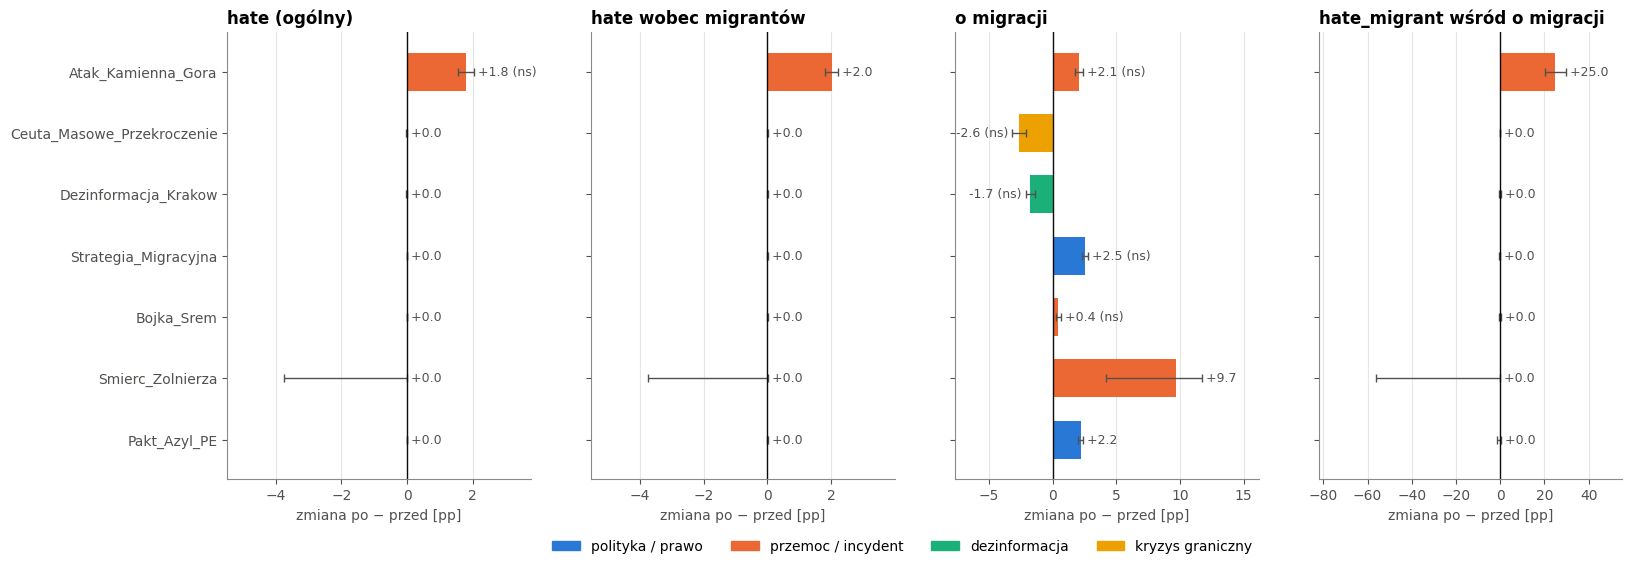

,największa,zmiana max [pp],najmniejsza,zmiana min [pp]
etykieta,,,,
hate,Atak_Kamienna_Gora,1.81,Pakt_Azyl_PE,0.00
hate_migrant,Atak_Kamienna_Gora,2.01,Smierc_Zolnierza,0.00
migrant,Smierc_Zolnierza,9.69,Ceuta_Masowe_Przekroczenie,-2.63
hate_migrant | migrant,Atak_Kamienna_Gora,24.98,Smierc_Zolnierza,0.00


In [5]:
order = eff[eff["etykieta"] == "hate"].sort_values("różnica pp")["event"].tolist()
fig, axes = plt.subplots(1, len(LABEL_SETS), figsize=(18, 0.6 * len(order) + 1.6), sharey=True)
y = np.arange(len(order))
for ax, name in zip(axes, LABEL_SETS):
    e = eff[eff["etykieta"] == name].set_index("event").loc[order]
    ax.barh(y, e["różnica pp"], height=0.62, color=[TYPE_COLORS[t] for t in e["typ"]])
    ax.errorbar(e["różnica pp"], y, xerr=[e["różnica pp"] - e["CI lo pp"], e["CI hi pp"] - e["różnica pp"]],
                fmt="none", ecolor=INK2, capsize=3, lw=1)
    for yi, (v, lo, hi, sig) in enumerate(zip(e["różnica pp"], e["CI lo pp"], e["CI hi pp"], e["istotne"])):
        right = v >= 0
        ax.text(hi if right else lo, yi, f" {v:+.1f}{'' if sig else ' (ns)'} " , va="center",
                ha="left" if right else "right", color=INK2, fontsize=9)
    ax.axvline(0, color=INK, lw=1)
    ax.margins(x=0.3)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.set_xlabel("zmiana po − przed [pp]")
    ax.set_title(LABEL_NAMES[name] if len(LABEL_NAMES[name]) < 30 else "hate_migrant wśród o migracji")
axes[0].set_yticks(y, order)
type_legend(fig)
plt.show()

rank = (eff.sort_values("różnica pp", ascending=False).groupby("etykieta", sort=False)
        .agg(największa=("event", "first"), **{"zmiana max [pp]": ("różnica pp", "first")},
             najmniejsza=("event", "last"), **{"zmiana min [pp]": ("różnica pp", "last")})
        .reindex(list(LABEL_SETS)))
display(rank.round(2))

## 3. Czy wydarzenia **ogólnie** podwyższają hejt? (test łączny)

Każde wydarzenie to jeden „eksperyment”. Pytamy, czy **typowo** po wydarzeniu jest więcej hejtu. Trzy podejścia:

1. **Test znaków** – najprostszy: w ilu wydarzeniach z `k` odsetek wzrósł? Gdyby wydarzenia nic nie zmieniały,
   wzrost i spadek byłyby równie prawdopodobne (jak rzut monetą). p = szansa, że przypadkiem wyjdzie tyle wzrostów lub więcej.
2. **Metaanaliza efektów losowych** – łączy OR z poszczególnych wydarzeń w **jeden wspólny OR**. Wydarzenia z dokładniejszym
   wynikiem ważą więcej, a model zakłada, że każde wydarzenie może mieć *trochę inny* prawdziwy efekt
   (efekty losowe, DerSimonian–Laird + poprawka Hartung–Knapp, odpowiednia przy małej liczbie wydarzeń).
   **I²** = jaka część różnic między wydarzeniami to prawdziwe różnice, a nie szum (0% – wydarzenia działają tak samo,
   > 50% – wyraźnie różnie). **To główny wynik.**
3. **Jeden model na wszystkich komentarzach** – regresja `y ~ po + C(event)` z klastrami po wątku: wspólny efekt „po”
   przy porównaniu każdego wydarzenia z jego własnym okresem „przed”. Daje ten sam kierunek, ale traktuje efekt jako identyczny
   dla wszystkich wydarzeń, więc jest mniej ostrożny niż metaanaliza.

In [6]:
def meta_random(y, se):
    """Metaanaliza efektów losowych: DerSimonian–Laird + przedział Hartung–Knapp (t, k-1 df)."""
    y, se = np.asarray(y, float), np.asarray(se, float)
    k, w = len(y), 1 / se ** 2
    fixed = (w * y).sum() / w.sum()
    q = (w * (y - fixed) ** 2).sum()
    c = w.sum() - (w ** 2).sum() / w.sum()
    tau2 = max(0.0, (q - (k - 1)) / c) if k > 1 else 0.0
    ws = 1 / (se ** 2 + tau2)
    mu = (ws * y).sum() / ws.sum()
    if k == 1:
        return {"k": 1, "mu": mu, "lo": mu - 1.96 * se[0], "hi": mu + 1.96 * se[0], "p": 2 * stats.norm.sf(abs(mu / se[0])),
                "tau2": 0.0, "I2": np.nan, "p Q": np.nan}
    se_hk = max(np.sqrt((ws * (y - mu) ** 2).sum() / ((k - 1) * ws.sum())), np.sqrt(1 / ws.sum()))
    t = stats.t.ppf(1 - ALPHA / 2, k - 1)
    return {"k": k, "mu": mu, "lo": mu - t * se_hk, "hi": mu + t * se_hk, "p": 2 * stats.t.sf(abs(mu / se_hk), k - 1),
            "tau2": tau2, "I2": max(0.0, (q - (k - 1)) / q) if q > 0 else 0.0, "p Q": stats.chi2.sf(q, k - 1)}


pooled_rows = []
for name, (col, cond) in LABEL_SETS.items():
    e = eff[eff["etykieta"] == name]
    m = meta_random(e["log OR"], e["se"])
    d = all_df[all_df[cond]] if cond else all_df
    fe = smf.logit("y ~ po + C(event)", data=d.assign(y=d[col].astype(int))).fit(
        disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(d["thread"])[0]})
    n_up = int((e["różnica pp"] > 0).sum())
    pooled_rows.append({
        "etykieta": name, "wydarzeń": len(e), "wzrost w": f"{n_up}/{len(e)}",
        "istotny wzrost w": f"{int((e['istotne'] & (e['różnica pp'] > 0)).sum())}/{len(e)}",
        "p test znaków": stats.binomtest(n_up, len(e), 0.5, alternative="greater").pvalue,
        "średnia zmiana pp": e["różnica pp"].mean(),
        "OR łączny (meta)": np.exp(m["mu"]), "OR lo": np.exp(m["lo"]), "OR hi": np.exp(m["hi"]), "p meta": m["p"],
        "I²": m["I2"], "p heterogeniczności": m["p Q"],
        "OR model wspólny": np.exp(fe.params["po"]), "p model wspólny": fe.pvalues["po"],
    })
pooled = pd.DataFrame(pooled_rows).set_index("etykieta")
pooled["p meta (Holm)"] = multipletests(pooled["p meta"], method="holm")[1]
pooled["wspólny wzrost istotny (meta)"] = (pooled["p meta (Holm)"] < ALPHA) & (pooled["OR łączny (meta)"] > 1)
display(fmt_p(pooled, 3))

/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,wydarzeń,wzrost w,istotny wzrost w,p test znaków,średnia zmiana pp,OR łączny (meta),OR lo,OR hi,p meta,I²,p heterogeniczności,OR model wspólny,p model wspólny,p meta (Holm),wspólny wzrost istotny (meta)
etykieta,,,,,,,,,,,,,,,
hate,7,1/7,0/7,0.992,0.259,0.229,0.082,0.637,0.0124,0.866,5.32e-08,2.150,0.0587,0.0498,False
hate_migrant,7,1/7,1/7,0.992,0.288,0.238,0.075,0.761,0.0233,0.895,1.63e-10,2.975,0.00569,0.0699,False
migrant,7,5/7,2/7,0.227,1.799,1.754,0.866,3.550,0.0992,0.714,0.00186,1.251,0.299,0.0992,False
hate_migrant | migrant,7,1/7,1/7,0.992,3.569,0.177,0.037,0.839,0.0345,0.914,4.3e-13,2.778,0.00235,0.0699,False


### Wykres lasu (forest plot)

Każdy wiersz to jedno wydarzenie: kropka = OR, kreska = 95% CI. Romb na dole = **wspólny OR z metaanalizy**.
Linia przerywana OR = 1 oznacza „brak zmiany”. Jeśli kreska/romb nie przecina tej linii – zmiana jest istotna.

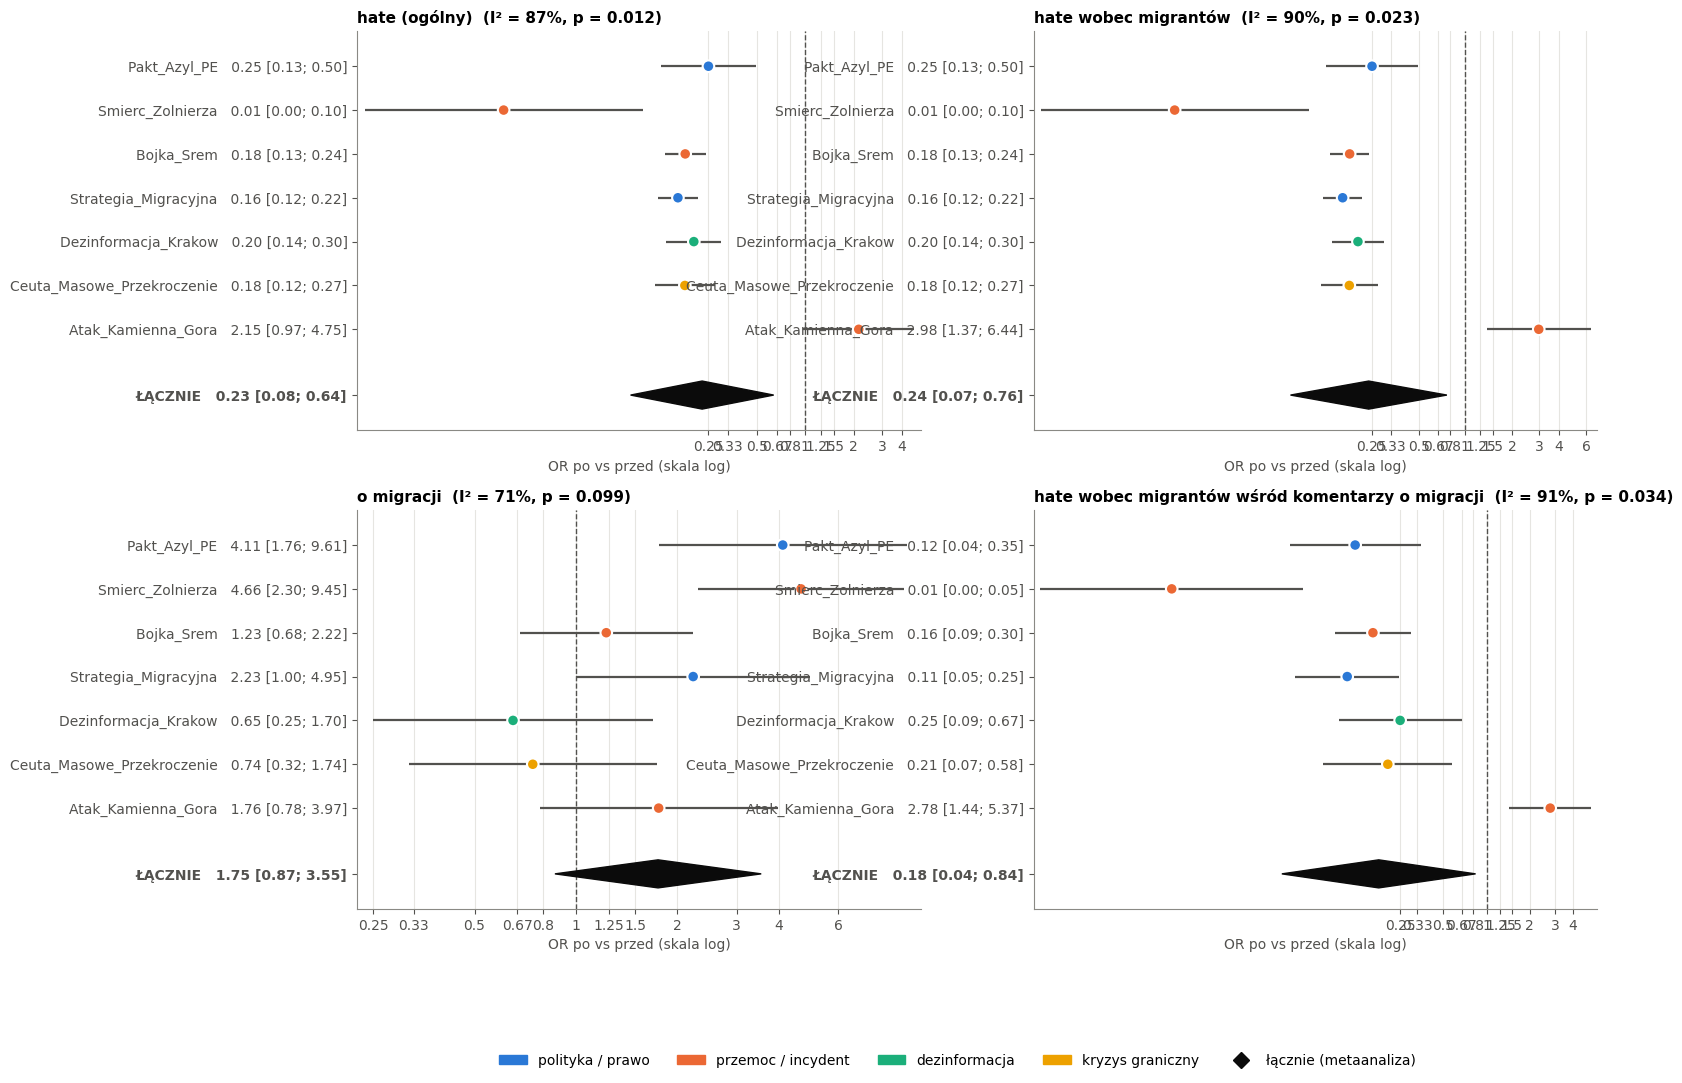

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(16, 2 * (0.5 * len(EVENT_ORDER) + 2.2)))
for ax, name in zip(axes.flat, LABEL_SETS):
    e = eff[eff["etykieta"] == name].set_index("event").loc[EVENT_ORDER]
    r = pooled.loc[name]
    y = np.arange(len(EVENT_ORDER))[::-1] + 1.5
    ax.hlines(y, e["OR lo"], e["OR hi"], color=INK2, lw=1.6)
    ax.scatter(e["OR"], y, s=70, color=[TYPE_COLORS[t] for t in e["typ"]], edgecolor="white", linewidth=1.5, zorder=3)
    ax.fill([r["OR lo"], r["OR łączny (meta)"], r["OR hi"], r["OR łączny (meta)"]], [0, 0.32, 0, -0.32], color=INK, zorder=3)
    ax.axvline(1, color=INK2, ls="--", lw=1)
    ax.set_xscale("log")
    xmin, xmax = min(e["OR lo"].min(), r["OR lo"]) * 0.9, max(e["OR hi"].max(), r["OR hi"]) * 1.1
    ax.set_xlim(xmin, xmax)
    ticks = [t for t in [0.25, 0.33, 0.5, 0.67, 0.8, 1, 1.25, 1.5, 2, 3, 4, 6] if xmin <= t <= xmax]
    ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
    ax.xaxis.set_minor_locator(mticker.NullLocator())
    labels = [f"{ev}   {o:.2f} [{lo:.2f}; {hi:.2f}]" for ev, o, lo, hi in zip(e.index, e["OR"], e["OR lo"], e["OR hi"])]
    ax.set_yticks([0, *y[::-1]], [f"ŁĄCZNIE   {r['OR łączny (meta)']:.2f} [{r['OR lo']:.2f}; {r['OR hi']:.2f}]", *labels[::-1]])
    ax.get_yticklabels()[0].set_fontweight("bold")
    ax.set_ylim(-0.8, y.max() + 0.8)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.set_xlabel("OR po vs przed (skala log)")
    i2 = "–" if np.isnan(r["I²"]) else f"{r['I²']:.0%}"
    ax.set_title(f"{LABEL_NAMES[name]}  (I² = {i2}, p = {r['p meta']:.2g})", fontsize=11)
type_legend(fig, extra=[(plt.Line2D([], [], marker="D", ls="", ms=8, color=INK), "łącznie (metaanaliza)")])
plt.show()

### 3b. Analiza wrażliwości: okna bez nakładania

Te same obliczenia (efekt każdego wydarzenia + metaanaliza), ale każde wydarzenie ma **symetryczne okno ±`TRIM_WINDOW` dni**
dobrane tak, żeby żaden komentarz nie należał do dwóch wydarzeń. Jeśli wnioski są podobne jak wyżej – są odporne na
nakładanie się okien. Jeśli się zmieniają – trzeba to uwzględnić w interpretacji.

In [8]:
# symetryczne okno bez nakładania: 2·W < odległość do najbliższego wydarzenia, maks. tyle, ile jest w danych
dates = {e: pd.Timestamp(EVENTS[e]) for e in EVENT_ORDER}
max_w = int(min(-all_df["relative_day"].min(), all_df["relative_day"].max()))
TRIM_WINDOW = {e: max(1, min(max_w, min([(abs((dates[e] - dates[o]).days) - 1) // 2 for o in EVENT_ORDER if o != e], default=max_w)))
               for e in EVENT_ORDER}
print("okno bez nakładania (± dni):", TRIM_WINDOW)

trim_df = pd.concat([all_df[(all_df["event"] == e) & all_df["relative_day"].between(-w, w)] for e, w in TRIM_WINDOW.items()])

rows = []
for event in EVENT_ORDER:
    d = trim_df[trim_df["event"] == event]
    for name, (col, cond) in LABEL_SETS.items():
        dd = d[d[cond]] if cond else d
        rows.append({"etykieta": name, "event": event, **event_effect(dd, col)})
eff_trim = pd.DataFrame(rows)

cmp_rows = []
trim_res = {}
for name in LABEL_SETS:
    a = eff[eff["etykieta"] == name].set_index("event")
    b = eff_trim[eff_trim["etykieta"] == name].set_index("event")
    for ev in EVENT_ORDER:
        cmp_rows.append({"etykieta": name, "event": ev, "okno": f"±{TRIM_WINDOW[ev]}",
                         "zmiana pp (±28)": a.loc[ev, "różnica pp"], "zmiana pp (bez nakładania)": b.loc[ev, "różnica pp"],
                         "OR (±28)": a.loc[ev, "OR"], "OR (bez nakładania)": b.loc[ev, "OR"],
                         "p (bez nakładania)": b.loc[ev, "p"]})
    m = meta_random(b["log OR"], b["se"])
    cmp_rows.append({"etykieta": name, "event": "ŁĄCZNIE (meta)", "okno": "",
                     "zmiana pp (±28)": a["różnica pp"].mean(), "zmiana pp (bez nakładania)": b["różnica pp"].mean(),
                     "OR (±28)": pooled.loc[name, "OR łączny (meta)"], "OR (bez nakładania)": np.exp(m["mu"]),
                     "p (bez nakładania)": m["p"]})
    trim_res[name] = {"OR meta bez nakładania": np.exp(m["mu"]), "OR lo bez nakładania": np.exp(m["lo"]),
                      "OR hi bez nakładania": np.exp(m["hi"]), "p meta bez nakładania": m["p"],
                      "wzrost w (bez nakładania)": f"{int((b['różnica pp'] > 0).sum())}/{len(b)}"}
pooled = pooled.join(pd.DataFrame(trim_res).T.astype({"OR meta bez nakładania": float, "OR lo bez nakładania": float,
                                                     "OR hi bez nakładania": float, "p meta bez nakładania": float}))
display(fmt_p(pd.DataFrame(cmp_rows).set_index(["etykieta", "event"]), 3))

okno bez nakładania (± dni): {'Pakt_Azyl_PE': 7, 'Smierc_Zolnierza': 7, 'Bojka_Srem': 7, 'Strategia_Migracyjna': 7, 'Dezinformacja_Krakow': 7, 'Ceuta_Masowe_Przekroczenie': 7, 'Atak_Kamienna_Gora': 7}


/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-pa

/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-pa

/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-pa

/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-pa

okno  zmiana pp (±28)  \
etykieta               event                                              
hate                   Pakt_Azyl_PE                 ±7            0.000   
                       Smierc_Zolnierza             ±7            0.000   
                       Bojka_Srem                   ±7            0.000   
                       Strategia_Migracyjna         ±7            0.000   
                       Dezinformacja_Krakow         ±7            0.000   
                       Ceuta_Masowe_Przekroczenie   ±7            0.000   
                       Atak_Kamienna_Gora           ±7            1.811   
                       ŁĄCZNIE (meta)                             0.259   
hate_migrant           Pakt_Azyl_PE                 ±7            0.000   
                       Smierc_Zolnierza             ±7            0.000   
                       Bojka_Srem                   ±7            0.000   
                       Strategia_Migracyjna         ±7            0.000   
                       Dezinformacja_Krakow         ±7            0.000   
                       Ceuta_Masowe_Przekroczenie   ±7            0.000   
                       Atak_Kamienna_Gora           ±7            2.014   
                       ŁĄCZNIE (meta)                             0.288   
migrant                Pakt_Azyl_PE                 ±7            2.201   
                       Smierc_Zolnierza             ±7            9.685   
                       Bojka_Srem                   ±7            0.442   
                       Strategia_Migracyjna         ±7            2.530   
                       Dezinformacja_Krakow         ±7           -1.738   
                       Ceuta_Masowe_Przekroczenie   ±7           -2.629   
                       Atak_Kamienna_Gora           ±7            2.105   
                       ŁĄCZNIE (meta)                             1.799   
hate_migrant | migrant Pakt_Azyl_PE                 ±7            0.000   
                       Smierc_Zolnierza             ±7            0.000   
                       Bojka_Srem                   ±7            0.000   
                       Strategia_Migracyjna         ±7            0.000   
                       Dezinformacja_Krakow         ±7            0.000   
                       Ceuta_Masowe_Przekroczenie   ±7            0.000   
                       Atak_Kamienna_Gora           ±7           24.980   
                       ŁĄCZNIE (meta)                             3.569   

                                                   zmiana pp (bez nakładania)  \
etykieta               event                                                    
hate                   Pakt_Azyl_PE                                     0.000   
                       Smierc_Zolnierza                                 0.000   
                       Bojka_Srem                                       0.000   
                       Strategia_Migracyjna                             0.000   
                       Dezinformacja_Krakow                             0.000   
                       Ceuta_Masowe_Przekroczenie                       0.000   
                       Atak_Kamienna_Gora                               0.797   
                       ŁĄCZNIE (meta)                                   0.114   
hate_migrant           Pakt_Azyl_PE                                     0.000   
                       Smierc_Zolnierza                                 0.000   
                       Bojka_Srem                                       0.000   
                       Strategia_Migracyjna                             0.000   
                       Dezinformacja_Krakow                             0.000   
                       Ceuta_Masowe_Przekroczenie                       0.000   
                       Atak_Kamienna_Gora                               0.987   
                       ŁĄCZNIE (meta)                                   0.141   
migrant                Pakt_Azyl_PE      

## 4. Czy efekt zależy od typu wydarzenia?

- **Tabela**: średnia zmiana (pp) i łączny OR (metaanaliza) osobno dla każdego typu i zasięgu.
- **Test różnicy typów**: w modelu `y ~ C(event) + po + po:C(typ)` (klastry po wątku) człon `po:C(typ)` mówi,
  czy efekt „po” różni się między typami. p < 0.05 → typy reagują inaczej.

⚠️ **Uwaga:** w każdym typie jest tylko 1–3 wydarzeń, więc „typ” prawie pokrywa się z konkretnym wydarzeniem.
Ten test nie odróżni „to typ wydarzenia tak działa” od „to akurat to jedno wydarzenie tak działało”.
Traktuj tę część **opisowo**, nie jako mocny dowód.

In [9]:
def group_test(d, col, grp):
    m = smf.logit(f"y ~ C(event) + po + po:C({grp})", data=d.assign(y=d[col].astype(int))).fit(
        disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(d["thread"])[0]}, maxiter=200)
    idx = [i for i, n in enumerate(m.params.index) if n.startswith(f"po:C({grp})")]
    if not idx:
        return np.nan
    return float(m.wald_test(np.eye(len(m.params))[idx], scalar=True).pvalue)


type_rows, test_rows = [], []
for name, (col, cond) in LABEL_SETS.items():
    d = all_df[all_df[cond]] if cond else all_df
    test_rows.append({"etykieta": name, "p różnica typów": group_test(d, col, "typ"),
                      "p różnica zasięgu (PL vs zagranica)": group_test(d, col, "zasieg")})
    for grp in ["typ", "zasieg"]:
        for g, e in eff[eff["etykieta"] == name].groupby(grp, sort=False):
            m = meta_random(e["log OR"], e["se"])
            type_rows.append({"etykieta": name, "podział": grp, "grupa": g, "wydarzenia": ", ".join(e["event"]),
                              "średnia zmiana pp": e["różnica pp"].mean(), "OR łączny": np.exp(m["mu"]),
                              "OR lo": np.exp(m["lo"]), "OR hi": np.exp(m["hi"])})

by_type = pd.DataFrame(type_rows)
display(by_type.set_index(["etykieta", "podział", "grupa"]).round(2))
display(fmt_p(pd.DataFrame(test_rows).set_index("etykieta"), 3))

/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


wydarzenia  \
etykieta               podział grupa                                                                                                              
hate                   typ     polityka / prawo                                                              Pakt_Azyl_PE, Strategia_Migracyjna   
                               przemoc / incydent                                              Smierc_Zolnierza, Bojka_Srem, Atak_Kamienna_Gora   
                               dezinformacja                                                                               Dezinformacja_Krakow   
                               kryzys graniczny                                                                      Ceuta_Masowe_Przekroczenie   
                       zasieg  UE / zagranica                                                          Pakt_Azyl_PE, Ceuta_Masowe_Przekroczenie   
                               Polska              Smierc_Zolnierza, Bojka_Srem, Strategia_Migracyjna, Dezinformacja_Krakow, Atak_Kamienna_Gora   
hate_migrant           typ     polityka / prawo                                                              Pakt_Azyl_PE, Strategia_Migracyjna   
                               przemoc / incydent                                              Smierc_Zolnierza, Bojka_Srem, Atak_Kamienna_Gora   
                               dezinformacja                                                                               Dezinformacja_Krakow   
                               kryzys graniczny                                                                      Ceuta_Masowe_Przekroczenie   
                       zasieg  UE / zagranica                                                          Pakt_Azyl_PE, Ceuta_Masowe_Przekroczenie   
                               Polska              Smierc_Zolnierza, Bojka_Srem, Strategia_Migracyjna, Dezinformacja_Krakow, Atak_Kamienna_Gora   
migrant                typ     polityka / prawo                                                              Pakt_Azyl_PE, Strategia_Migracyjna   
                               przemoc / incydent                                              Smierc_Zolnierza, Bojka_Srem, Atak_Kamienna_Gora   
                               dezinformacja                                                                               Dezinformacja_Krakow   
                               kryzys graniczny                                                                      Ceuta_Masowe_Przekroczenie   
                       zasieg  UE / zagranica                                                          Pakt_Azyl_PE, Ceuta_Masowe_Przekroczenie   
                               Polska              Smierc_Zolnierza, Bojka_Srem, Strategia_Migracyjna, Dezinformacja_Krakow, Atak_Kamienna_Gora   
hate_migrant | migrant typ     polityka / prawo                                                              Pakt_Azyl_PE, Strategia_Migracyjna   
                               przemoc / incydent                                              Smierc_Zolnierza, Bojka_Srem, Atak_Kamienna_Gora   
                               dezinformacja                                                                               Dezinformacja_Krakow   
                               kryzys graniczny                                                                      Ceuta_Masowe_Przekroczenie   
                       zasieg  UE / zagranica                                                          Pakt_Azyl_PE, Ceuta_Masowe_Przekroczenie   
                               Polska              Smierc_Zolnierza, Bojka_Srem, Strategia_Migracyjna, Dezinformacja_Krakow, Atak_Kamienna_Gora   

                                                   średnia zmiana pp  \
etykieta               podział grupa                                   
hate                   typ     polityka / prawo                 0.00   
                               przemoc / incydent               0.60   
                      

,p różnica typów,p różnica zasięgu (PL vs zagranica)
etykieta,,
hate,3.56e-24,5.14e-16
hate_migrant,1.46e-06,1.74e-19
migrant,0.0318,0.643
hate_migrant | migrant,3.99e-31,2.26e-16


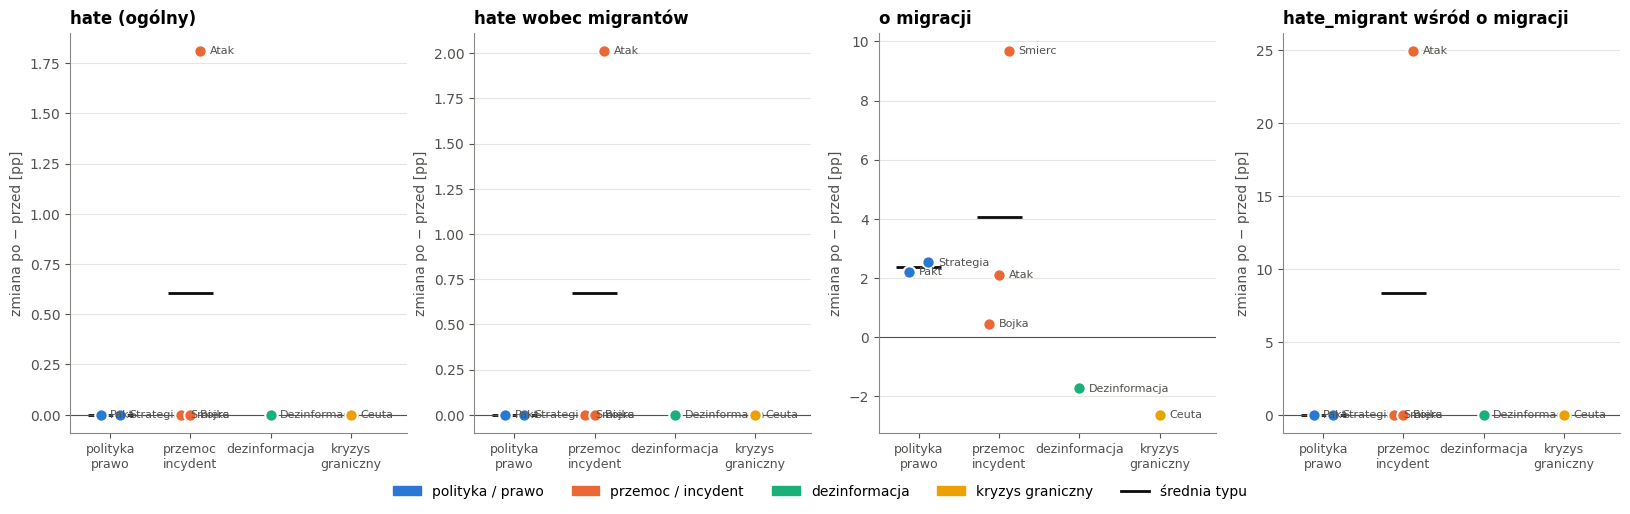

In [10]:
fig, axes = plt.subplots(1, len(LABEL_SETS), figsize=(20, 5.2), sharey=False)
for ax, name in zip(axes, LABEL_SETS):
    e = eff[eff["etykieta"] == name]
    for xi, t in enumerate(TYPE_ORDER):
        g = e[e["typ"] == t].sort_values("różnica pp")
        if g.empty:
            continue
        xs = xi + np.linspace(-0.12, 0.12, len(g)) if len(g) > 1 else np.array([xi])
        ax.scatter(xs, g["różnica pp"], s=80, color=TYPE_COLORS[t], edgecolor="white", linewidth=1.5, zorder=3)
        if len(g) > 1:
            ax.hlines(g["różnica pp"].mean(), xi - 0.28, xi + 0.28, color=INK, lw=2)
        for x_, v, ev in zip(xs, g["różnica pp"], g["event"]):
            ax.annotate(ev.split("_")[0], (x_, v), xytext=(7, 0), textcoords="offset points", va="center",
                        fontsize=8, color=INK2)
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_xticks(range(len(TYPE_ORDER)), [t.replace(" / ", "\n").replace(" ", "\n") for t in TYPE_ORDER], fontsize=9)
    ax.set_xlim(-0.5, len(TYPE_ORDER) - 0.3)
    ax.set_ylabel("zmiana po − przed [pp]")
    ax.set_title(LABEL_NAMES[name] if len(LABEL_NAMES[name]) < 30 else "hate_migrant wśród o migracji")
type_legend(fig, extra=[(plt.Line2D([], [], color=INK, lw=2), "średnia typu")])
plt.show()

### Wnioski z sekcji 4

1. **Formalnie typ i zasięg „mają znaczenie”** dla `hate`, `hate_migrant` i `migrant` (p różnicy typów 0.0003–0.001,
   p różnicy zasięgu 0.001–0.014). Ale przy 1–3 wydarzeniach na typ te p-value mierzą głównie to, że **wydarzenia różnią się
   między sobą** (I² = 80–90% w sekcji 3), a nie to, że różni się *typ*. To potwierdzenie heterogeniczności, a nie dowód na wpływ typu.
2. **Polityka / prawo** ma najwyższy średni wzrost (`hate` +2.5 pp, `hate_migrant` +2.4 pp, `migrant` +4.9 pp), ale prawie
   w całości to zasługa **Paktu o azylu** (+4.6 / +4.2 / +8.4 pp). Strategia migracyjna daje tylko +0.5 / +0.6 / +1.3 pp,
   dlatego łączny OR dla typu ma ogromny przedział (np. `hate`: 1.21 [0.14; 10.35]) – kierunek dodatni, ale nierozstrzygnięty.
3. **Przemoc / incydent** nie zmienia ogólnego hejtu (`hate` +0.25 pp, OR 1.01 [0.86; 1.18]). Rośnie natomiast **ilość rozmowy
   o migracji** po Bójce w Śremie (+9.7 pp) i Śmierci żołnierza (+4.0 pp). Wyjątkiem jest Atak w Kamiennej Górze (−6.7 pp `migrant`) –
   prawdopodobnie dlatego, że wypadł 16 dni po Ceucie: jego okres „przed” to okres „po” Ceuty (77% wspólnych komentarzy),
   więc punkt odniesienia był już podbity. Spadek utrzymuje się też w oknie ±7 dni bez nakładania (−8.2 pp), ale tam „przed”
   to nadal dni 9–15 po Ceucie, więc nie da się tych dwóch wydarzeń w pełni rozdzielić.
4. **Dezinformacja (Kraków)** to jedyny typ ze spójnym spadkiem: `migrant` −6.2 pp (OR 0.77 [0.62; 0.95]), `hate_migrant` −1.9 pp.
   Możliwe wyjaśnienie: sprostowanie fałszywej informacji wygasza temat. To jednak tylko jedno wydarzenie.
5. **Kryzys graniczny (Ceuta)** – brak efektu (`hate` −1.1 pp, OR 0.94 [0.85; 1.05]); poziom hejtu był wysoki już przed wydarzeniem
   (~27% `hate`), a okno „po” jest przemieszane z Atakiem w Kamiennej Górze.
6. **Zasięg UE / zagranica vs Polska**: wydarzenia zagraniczne średnio +1.7 pp `hate` vs ~0 pp dla Polski, ale grupa „zagranica”
   to tylko Pakt (+4.6) i Ceuta (−1.1), więc to znów różnica między dwoma wydarzeniami, nie efekt zasięgu.
7. **Najważniejsze:** dla `hate_migrant` **wśród komentarzy o migracji** różnic między typami i zasięgami **nie ma**
   (p = 0.17 i 0.70), a odsetek trzyma się w wąskim zakresie ~35–46% niezależnie od wydarzenia. Wydarzenia zmieniają więc głównie
   **to, jak dużo mówi się o migracji**, a nie **jak wrogo się o niej mówi** – wzrost `hate_migrant` po wydarzeniach (tam, gdzie
   występuje) wynika przede wszystkim ze wzrostu udziału tematu migracji.

**Podsumowanie:** typ wydarzenia nie jest dobrym predyktorem wzrostu hejtu – liczy się konkretne wydarzenie (szczególnie Pakt o azylu).
Żeby rzetelnie sprawdzić wpływ typu, potrzeba więcej wydarzeń w każdej kategorii.

## 5. Przebieg w czasie – wszystkie wydarzenia na wspólnej osi

Dla każdego wydarzenia: dzienny odsetek etykiety **minus jego własna średnia sprzed wydarzenia** (w pp),
wygładzony średnią kroczącą `ROLL_DAYS` dni. Dzięki temu wydarzenia o różnym „poziomie bazowym” da się położyć
na jednej osi. Gruba czarna linia = średnia wszystkich wydarzeń. Wartość > 0 = więcej niż zwykle przed wydarzeniem.

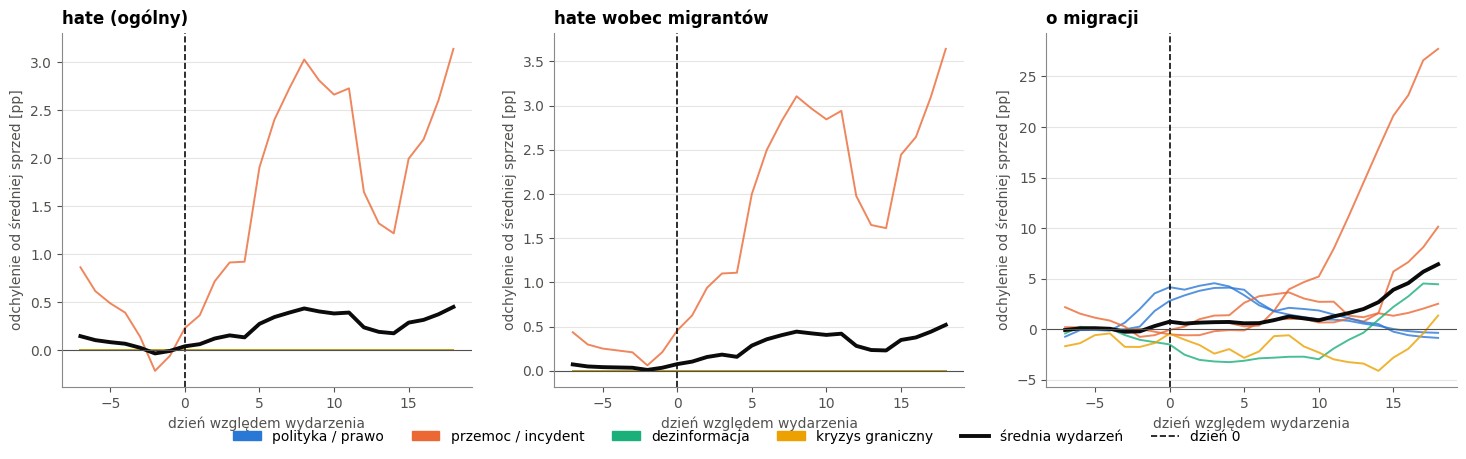

In [11]:
fig, axes = plt.subplots(1, len(LABELS), figsize=(18, 4.6))
for ax, lab in zip(axes, LABELS):
    curves = {}
    for ev in EVENT_ORDER:
        d = all_df[all_df["event"] == ev]
        g = d.groupby("relative_day")[lab].agg(["mean", "size"])
        g = g[g["size"] >= MIN_DAILY_N].reindex(range(d["relative_day"].min(), d["relative_day"].max() + 1))
        base = d.loc[d["okres"] == "przed", lab].mean()
        s = (100 * (g["mean"] - base)).rolling(ROLL_DAYS, center=True, min_periods=3).mean()
        curves[ev] = s
        ax.plot(s.index, s.values, color=TYPE_COLORS[EVENT_META[ev][0]], lw=1.4, alpha=0.8)
    avg = pd.DataFrame(curves).mean(axis=1)
    ax.plot(avg.index, avg.values, color=INK, lw=2.8)
    ax.axvline(0, color=INK, ls="--", lw=1.2)
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_xlabel("dzień względem wydarzenia")
    ax.set_ylabel("odchylenie od średniej sprzed [pp]")
    ax.set_title(LABEL_NAMES[lab])
type_legend(fig, extra=[(plt.Line2D([], [], color=INK, lw=2.8), "średnia wydarzeń"),
                        (plt.Line2D([], [], color=INK, ls="--", lw=1.2), "dzień 0")])
plt.show()

## 6. Aktywność: czy po wydarzeniu pisze się więcej?

Liczba komentarzy na dzień przed i po oraz krotność wzrostu. Korelacja Spearmana sprawdza, czy wydarzenia,
które bardziej „rozkręciły” dyskusję, mają też większy wzrost hejtu (przy kilku wydarzeniach – tylko orientacyjnie).

In [12]:
act = (all_df.groupby(["event", "okres"])
       .agg(n=("comment_id", "size"), dni=("relative_day", "nunique"))
       .assign(na_dzien=lambda x: x["n"] / x["dni"])["na_dzien"].unstack("okres")
       .reindex(EVENT_ORDER)[["przed", "po"]])
act.columns = ["komentarzy/dzień przed", "komentarzy/dzień po"]
act["wzrost ×"] = act["komentarzy/dzień po"] / act["komentarzy/dzień przed"]
for name in LABELS:
    act[f"zmiana {name} [pp]"] = eff[eff["etykieta"] == name].set_index("event")["różnica pp"]
display(act.round(2))
for name in LABELS:
    rho, p = stats.spearmanr(act["wzrost ×"], act[f"zmiana {name} [pp]"])
    print(f"Spearman: wzrost aktywności vs zmiana {name}: rho = {rho:.2f}, p = {p:.3g} (n = {len(act)})")

,komentarzy/dzień przed,komentarzy/dzień po,wzrost ×,zmiana hate [pp],zmiana hate_migrant [pp],zmiana migrant [pp]
event,,,,,,
Pakt_Azyl_PE,5138.14,2883.42,0.56,0.00,0.00,2.20
Smierc_Zolnierza,49.50,2515.53,50.82,0.00,0.00,9.69
Bojka_Srem,3994.14,4309.74,1.08,0.00,0.00,0.44
Strategia_Migracyjna,3671.29,4833.68,1.32,0.00,0.00,2.53
Dezinformacja_Krakow,2510.43,2135.11,0.85,0.00,0.00,-1.74
Ceuta_Masowe_Przekroczenie,2423.00,2639.58,1.09,0.00,0.00,-2.63
Atak_Kamienna_Gora,2119.00,4979.37,2.35,1.81,2.01,2.11


Spearman: wzrost aktywności vs zmiana hate: rho = 0.41, p = 0.363 (n = 7)
Spearman: wzrost aktywności vs zmiana hate_migrant: rho = 0.41, p = 0.363 (n = 7)
Spearman: wzrost aktywności vs zmiana migrant: rho = 0.46, p = 0.294 (n = 7)


## 7. Słowa w hejcie wobec migrantów

Tokenizacja jak w notebookach pojedynczych wydarzeń (małe litery, bez linków, ≥ 3 litery, bez stop-słów, bez lematyzacji).

- **7.1** najczęstsze słowa w `hate_migrant` – łącznie i w każdym wydarzeniu,
- **7.2** słowa **charakterystyczne** dla wydarzenia – częstsze w hejcie tego wydarzenia niż w hejcie pozostałych
  (ważony log-odds ratio z priorem Dirichleta, Monroe i in. 2008; `z` > 2 ≈ wyraźnie częstsze),
- **7.3** słowa, które **najbardziej rosną po wydarzeniu** (wszystkie wydarzenia razem, po vs przed).

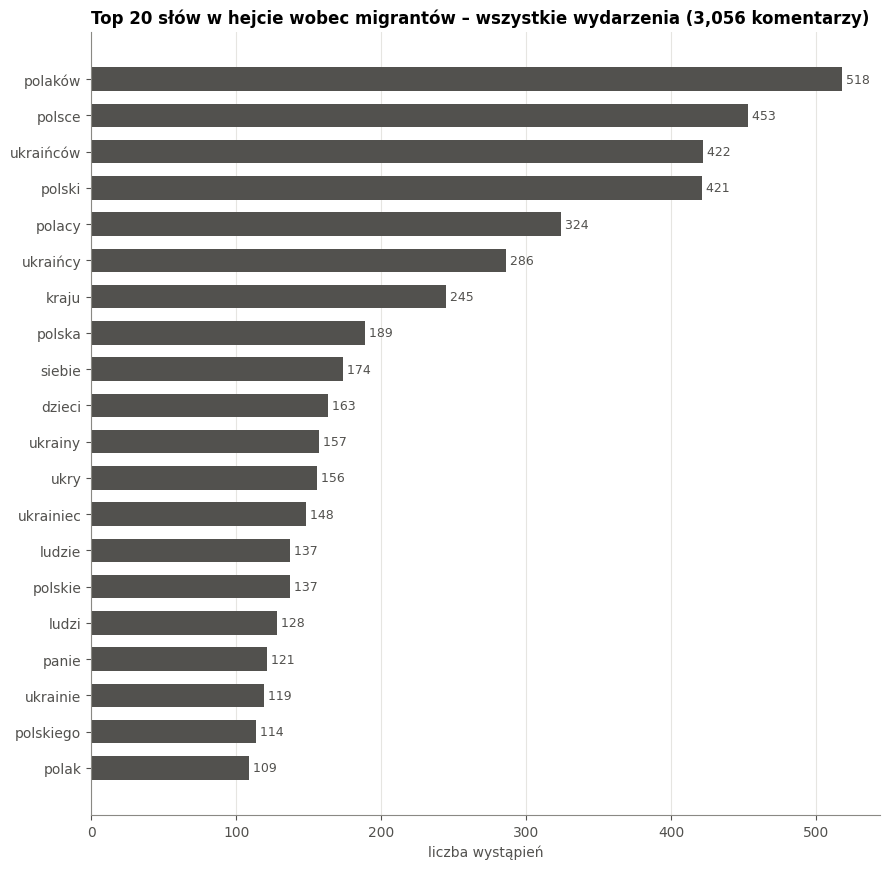

Najczęstsze słowa w hate_migrant w każdym wydarzeniu:


,Pakt_Azyl_PE,Smierc_Zolnierza,Bojka_Srem,Strategia_Migracyjna,Dezinformacja_Krakow,Ceuta_Masowe_Przekroczenie,Atak_Kamienna_Gora
1,,,,,,,polaków (518)
2,,,,,,,polsce (453)
3,,,,,,,ukraińców (422)
4,,,,,,,polski (421)
5,,,,,,,polacy (324)
6,,,,,,,ukraińcy (286)
7,,,,,,,kraju (245)
8,,,,,,,polska (189)
9,,,,,,,siebie (174)
10,,,,,,,dzieci (163)


In [13]:
STOPWORDS_PL = set('''
a aby ach acz aczkolwiek aj albo ale ależ ani aż bardziej bardzo bez bo bowiem by byli bym bynajmniej być był była było były będzie będą
cali cała cały chce chcą ci cię ciebie co cokolwiek coraz coś czasami czasem czemu czy czyli często daleko dla dlaczego dlatego do dobrze
dokąd dość dużo dwa dwaj dwie dwoje dziś dzisiaj gdy gdyby gdyż gdzie gdziekolwiek gdzieś go i ich ile im inna inne inny innych iż ja ją
jak jakaś jakby jaki jakichś jakie jakiś jakiż jakkolwiek jako jakoś je jeden jedna jedno jednak jednakże jego jej jemu jest jestem jeszcze
jeśli jeżeli już ją każdy kiedy kilka kimś kto ktokolwiek ktoś która które którego której który których którym którzy ku lat lecz lub
ma mają mam mamy mało mi mimo między mną mnie mogą moi moim moja moje może możliwe można mój mu musi my na nad nam nami nas nasi nasz nasza
nasze naszego naszych natomiast natychmiast nawet nic nich nie niech niego niej niemu nigdy nim nimi niż no o obok od około on ona one oni
ono oraz oto owszem pan pana pani po pod podczas pomimo ponad ponieważ powinien powinna powinni powinno poza prawie przecież przed przede
przedtem przez przy roku również sam sama są się skąd sobie sobą sposób swoje ta tak taka taki takie także tam te tego tej temu ten teraz
też to tobą tobie toteż trzeba tu tutaj twoi twoim twoja twoje twym twój ty tych tylko tym u w wam wami was wasz wasza wasze we według
wiele wielu więc więcej wszyscy wszystkich wszystkie wszystkim wszystko wtedy wy właśnie z za zapewne zawsze ze zł znowu znów został żaden
żadna żadne żadnych że żeby tez juz sie jak ktory ktora ktore bylo byl beda bedzie moze takze zeby ze tylko wiec niz przez tego tym jeszcze
tych tej mnie mieć mają ma mial miał było będą bylo były jakis jakies cos nikt nikogo niczego wszystkiego swój swoją swojej swoich swoim
naszym tymi takich takiej takim tamtych coś ktoś kogoś czegoś bym byś byście byśmy będę będziesz będziemy jestes jesteś jesteśmy
http https www com html pdf amp quot xd xdd xddd lenny bo tam tu oni ich sa sā też dla gdzie potem teraz chyba raczej
'''.split())

URL_RE = re.compile(r"https?://\S+|www\.\S+|@\w+")
TOKEN_RE = re.compile(r"[a-ząćęłńóśźż]{3,}")


def tokenize(text):
    return [t for t in TOKEN_RE.findall(URL_RE.sub(" ", text.lower())) if t not in STOPWORDS_PL]


def count_words(texts):
    return Counter(t for txt in texts for t in tokenize(txt))


hm = all_df[all_df["hate_migrant"]]
counts = {ev: count_words(hm.loc[hm["event"] == ev, "text"]) for ev in EVENT_ORDER}
total = sum(counts.values(), Counter())

top = pd.DataFrame(total.most_common(TOP_N_WORDS), columns=["słowo", "liczba"])
fig, ax = plt.subplots(figsize=(9, 0.38 * TOP_N_WORDS + 1.2))
ax.barh(top["słowo"][::-1], top["liczba"][::-1], color=INK2, height=0.65)
for yi, v in enumerate(top["liczba"][::-1]):
    ax.text(v, yi, f" {v}", va="center", color=INK2, fontsize=9)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("liczba wystąpień")
ax.set_title(f"Top {TOP_N_WORDS} słów w hejcie wobec migrantów – wszystkie wydarzenia ({len(hm):,} komentarzy)")
plt.tight_layout()
plt.show()

print("Najczęstsze słowa w hate_migrant w każdym wydarzeniu:")
display(pd.DataFrame({ev: [f"{w} ({n})" for w, n in counts[ev].most_common(TOP_N_WORDS)]
                          + [""] * (TOP_N_WORDS - len(counts[ev].most_common(TOP_N_WORDS))) for ev in EVENT_ORDER},
                     index=range(1, TOP_N_WORDS + 1)))

In [14]:
def log_odds(c1, c2, prior, min_count=5):
    """Ważony log-odds ratio z informatywnym priorem Dirichleta (Monroe i in. 2008); z > 0 = częstsze w c1."""
    n1, n2, a0 = sum(c1.values()), sum(c2.values()), sum(prior.values())
    rows = []
    for w, y1 in c1.items():
        if y1 < min_count:
            continue
        a, y2 = prior[w], c2.get(w, 0)
        delta = np.log((y1 + a) / (n1 + a0 - y1 - a)) - np.log((y2 + a) / (n2 + a0 - y2 - a))
        rows.append((w, y1, y2, delta / np.sqrt(1 / (y1 + a) + 1 / (y2 + a))))
    return pd.DataFrame(rows, columns=["słowo", "n", "n porównanie", "z"]).sort_values("z", ascending=False)


distinct = {}
for ev in EVENT_ORDER:
    rest = total - counts[ev]
    lo_ = log_odds(counts[ev], rest, total).head(TOP_N_WORDS)
    distinct[ev] = [f"{w} (z={z:.1f})" for w, z in zip(lo_["słowo"], lo_["z"])]
print("7.2 Słowa charakterystyczne dla hejtu w danym wydarzeniu (vs hejt w pozostałych wydarzeniach):")
display(pd.DataFrame({ev: v + [""] * (TOP_N_WORDS - len(v)) for ev, v in distinct.items()}, index=range(1, TOP_N_WORDS + 1)))

7.2 Słowa charakterystyczne dla hejtu w danym wydarzeniu (vs hejt w pozostałych wydarzeniach):


,Pakt_Azyl_PE,Smierc_Zolnierza,Bojka_Srem,Strategia_Migracyjna,Dezinformacja_Krakow,Ceuta_Masowe_Przekroczenie,Atak_Kamienna_Gora
1,,,,,,,początku (z=0.0)
2,,,,,,,stanowiska (z=0.0)
3,,,,,,,powodu (z=0.0)
4,,,,,,,ceucie (z=0.0)
5,,,,,,,powiedziała (z=0.0)
6,,,,,,,podobno (z=0.0)
7,,,,,,,letnią (z=0.0)
8,,,,,,,mieście (z=0.0)
9,,,,,,,boję (z=0.0)
10,,,,,,,bierze (z=0.0)


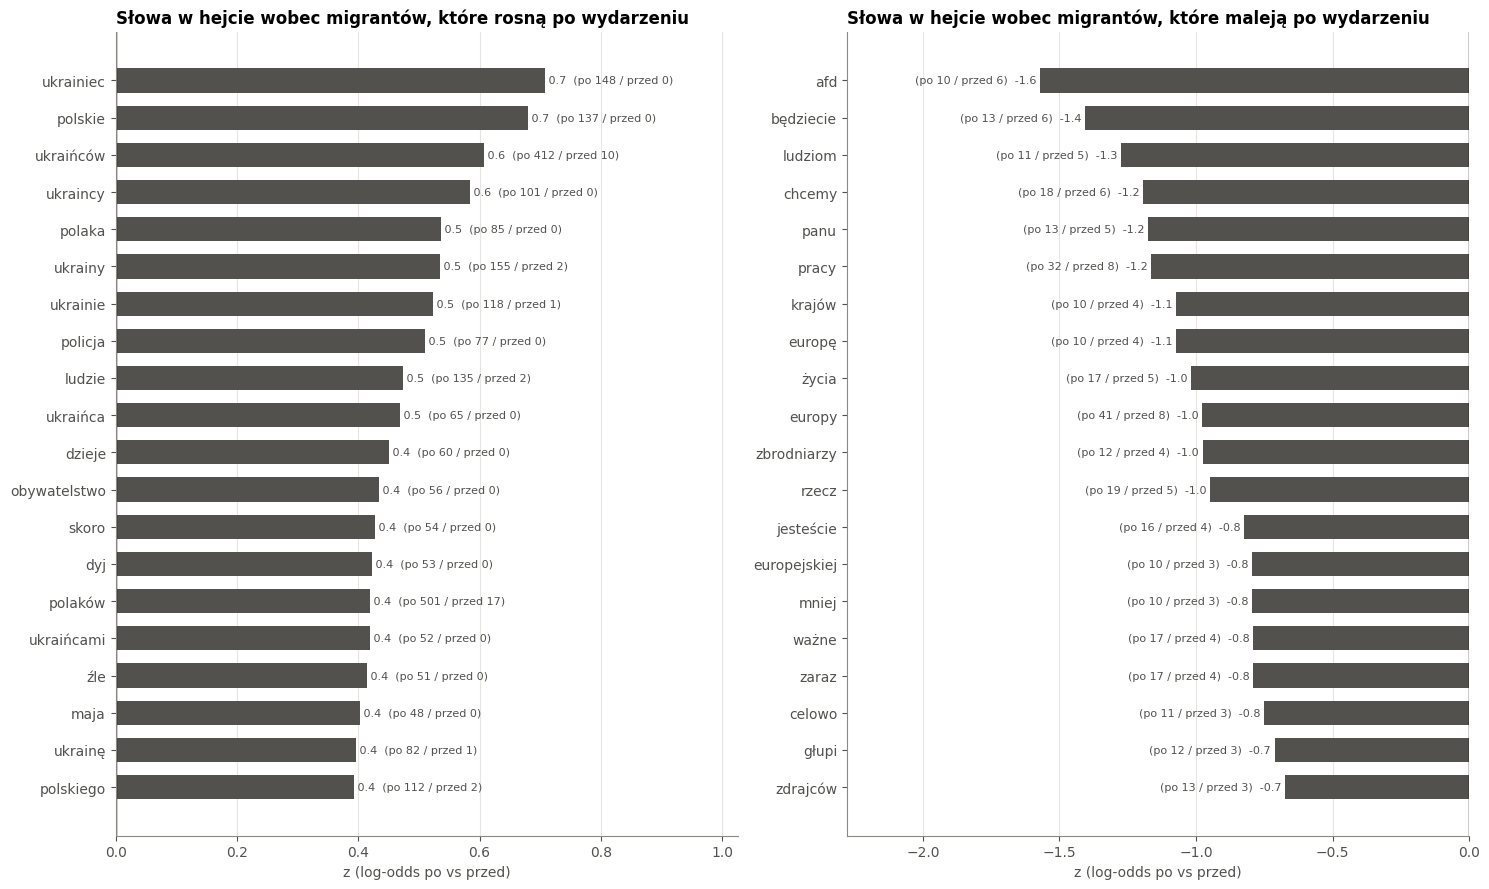

In [15]:
c_pre = count_words(hm.loc[hm["okres"] == "przed", "text"])
c_post = count_words(hm.loc[hm["okres"] == "po", "text"])
growth = log_odds(c_post, c_pre, c_pre + c_post, min_count=10)
grow = growth.head(TOP_N_WORDS)
fall = growth.sort_values("z").head(TOP_N_WORDS)

fig, axes = plt.subplots(1, 2, figsize=(15, 0.38 * TOP_N_WORDS + 1.4))
for ax, t, title in [(axes[0], grow, "rosną po wydarzeniu"), (axes[1], fall, "maleją po wydarzeniu")]:
    ax.barh(t["słowo"][::-1], t["z"][::-1], color=INK2, height=0.65)
    for yi, (z, n1, n0) in enumerate(zip(t["z"][::-1], t["n"][::-1], t["n porównanie"][::-1])):
        ax.text(z, yi, f" {z:.1f}  (po {n1} / przed {n0})" if z > 0 else f"(po {n1} / przed {n0})  {z:.1f} ",
                va="center", ha="left" if z > 0 else "right", color=INK2, fontsize=8)
    ax.axvline(0, color=INK, lw=1)
    ax.margins(x=0.45)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.set_xlabel("z (log-odds po vs przed)")
    ax.set_title(f"Słowa w hejcie wobec migrantów, które {title}")
plt.tight_layout()
plt.show()

## 8. Kogo obrażano? Grupy w hejcie wobec migrantów po wydarzeniu

Odsetek komentarzy `hate_migrant` z okresu **po** wydarzeniu, które wymieniają daną grupę (słowa kluczowe jak w notebookach
pojedynczych wydarzeń; komentarz może trafić do kilku grup). Ciemniejsze pole = większy odsetek.

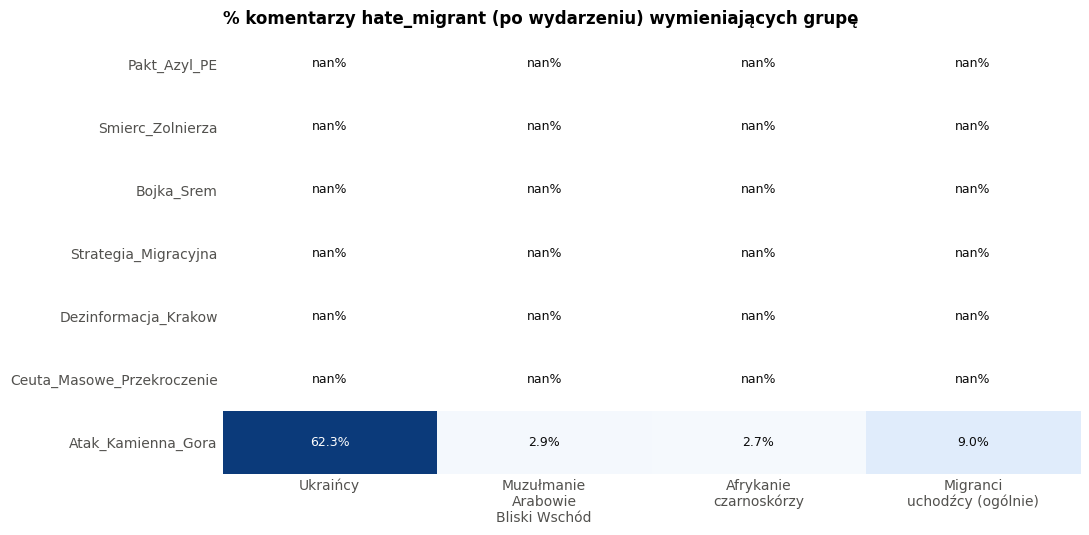

Zmiana po − przed [pp]:


,Ukraińcy,Muzułmanie / Arabowie / Bliski Wschód,Afrykanie / czarnoskórzy,Migranci / uchodźcy (ogólnie)
event,,,,
Pakt_Azyl_PE,NaN,NaN,NaN,NaN
Smierc_Zolnierza,NaN,NaN,NaN,NaN
Bojka_Srem,NaN,NaN,NaN,NaN
Strategia_Migracyjna,NaN,NaN,NaN,NaN
Dezinformacja_Krakow,NaN,NaN,NaN,NaN
Ceuta_Masowe_Przekroczenie,NaN,NaN,NaN,NaN
Atak_Kamienna_Gora,18.8,-3.5,-6.9,-5.8


In [16]:
TARGET_GROUPS = {
    "Ukraińcy": r"ukrai|ukraiń|\bukr|ukrop|bander|\bupa\b|upain|upowc|slava|sława|chachoł|chochoł",
    "Muzułmanie / Arabowie / Bliski Wschód": r"muzu?ł?m|muslim|islam|arab|allah|ciap|kozoj|talib|afga|syryj|syri|irak|turk|turc|pakist|czeczen|kebab|szariat|meczet",
    "Afrykanie / czarnoskórzy": r"murzyn|afryk|czarn|bambus|asfalt|nigeri|somal|erytre|małp|malp",
    "Migranci / uchodźcy (ogólnie)": r"migran|imigran|uchodź|uchodz|nachodź|nachodz|najeźdź|najezdz|relokac|azyl|ubogac|nielegal|przybysz|inwazj",
}
low = hm["text"].str.lower()
grp = pd.DataFrame({g: low.str.contains(rx, regex=True) for g, rx in TARGET_GROUPS.items()})
grp_pct = {okres: 100 * grp[hm["okres"] == okres].groupby(hm["event"]).mean().reindex(EVENT_ORDER)
           for okres in ["przed", "po"]}

tab = grp_pct["po"]
fig, ax = plt.subplots(figsize=(11, 0.55 * len(EVENT_ORDER) + 1.6))
ax.imshow(tab.values, cmap=BLUES, aspect="auto", vmin=0)
for (i, j), v in np.ndenumerate(tab.values):
    ax.text(j, i, f"{v:.1f}%", ha="center", va="center", fontsize=9,
            color="white" if v > 0.45 * np.nanmax(tab.values) else INK)
ax.set_xticks(range(tab.shape[1]), [c.replace(" / ", "\n") for c in tab.columns])
ax.set_yticks(range(len(tab)), tab.index)
ax.grid(False)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("% komentarzy hate_migrant (po wydarzeniu) wymieniających grupę")
plt.tight_layout()
plt.show()

print("Zmiana po − przed [pp]:")
display((grp_pct["po"] - grp_pct["przed"]).round(1))

## 10. Kanały: czy hejt różni się między kanałami?

Kanał to wartość `keywords` z `clean/posts.csv`, dołączona do komentarzy po `post_id`. Pytania:

1. jak kanały różnią się **poziomem** `migrant`, `hate`, `hate_migrant` (w całej próbie),
2. czy **po wydarzeniu** hejt rośnie bardziej w jednych kanałach niż w innych (model `y ~ po + C(event)`, błędy klastrowane po wątku, Holm w obrębie etykiety),
3. czy różnice między kanałami są istotne – poziom (`C(kanal)`) i reakcja na wydarzenie (`po:C(kanal)`) – oraz jakie słowa wyróżniają hejt w danym kanale.

Kanały z mniej niż `MIN_CHANNEL_N` komentarzami są łączone w grupę „(inne, małe kanały)”. Komentarze z nakładających się okien wydarzeń liczą się w każdym wydarzeniu osobno.

Komentarze bez przypisanego kanału (ich `post_id` nie występuje w `clean/posts.csv`) są w tej sekcji pomijane.

analiza kanałów: 571,640 komentarzy z przypisanym kanałem (96.8% wszystkich)


Kanałów: 10, po scaleniu małych: 10


,komentarzy,wydarzeń,postów,% migrant,% hate,% hate_migrant,% hate_migrant | migrant,udział przed %,udział po %
kanal_gr,,,,,,,,,
Kanal_Zero,302534,7,467,4.22,0.30,0.24,5.75,56.23,51.91
Telewizja_Republika,140588,7,659,4.96,0.43,0.36,7.26,24.69,24.56
tvp_info,42330,7,417,3.18,0.78,0.66,20.91,7.00,7.53
SławomirMentzen,39607,7,117,11.85,3.85,3.61,30.43,5.51,7.37
Onet,20479,7,135,4.32,0.42,0.38,8.82,2.38,3.95
polsatnews.pl,13200,7,397,0.10,0.01,0.01,7.69,2.26,2.33
Praktycznieopieniadzach,8942,7,22,3.85,0.10,0.10,2.62,1.38,1.62
TVN24,3613,7,129,0.66,0.00,0.00,0.00,0.50,0.67
Orb,339,4,5,0.00,0.00,0.00,NaN,0.05,0.06


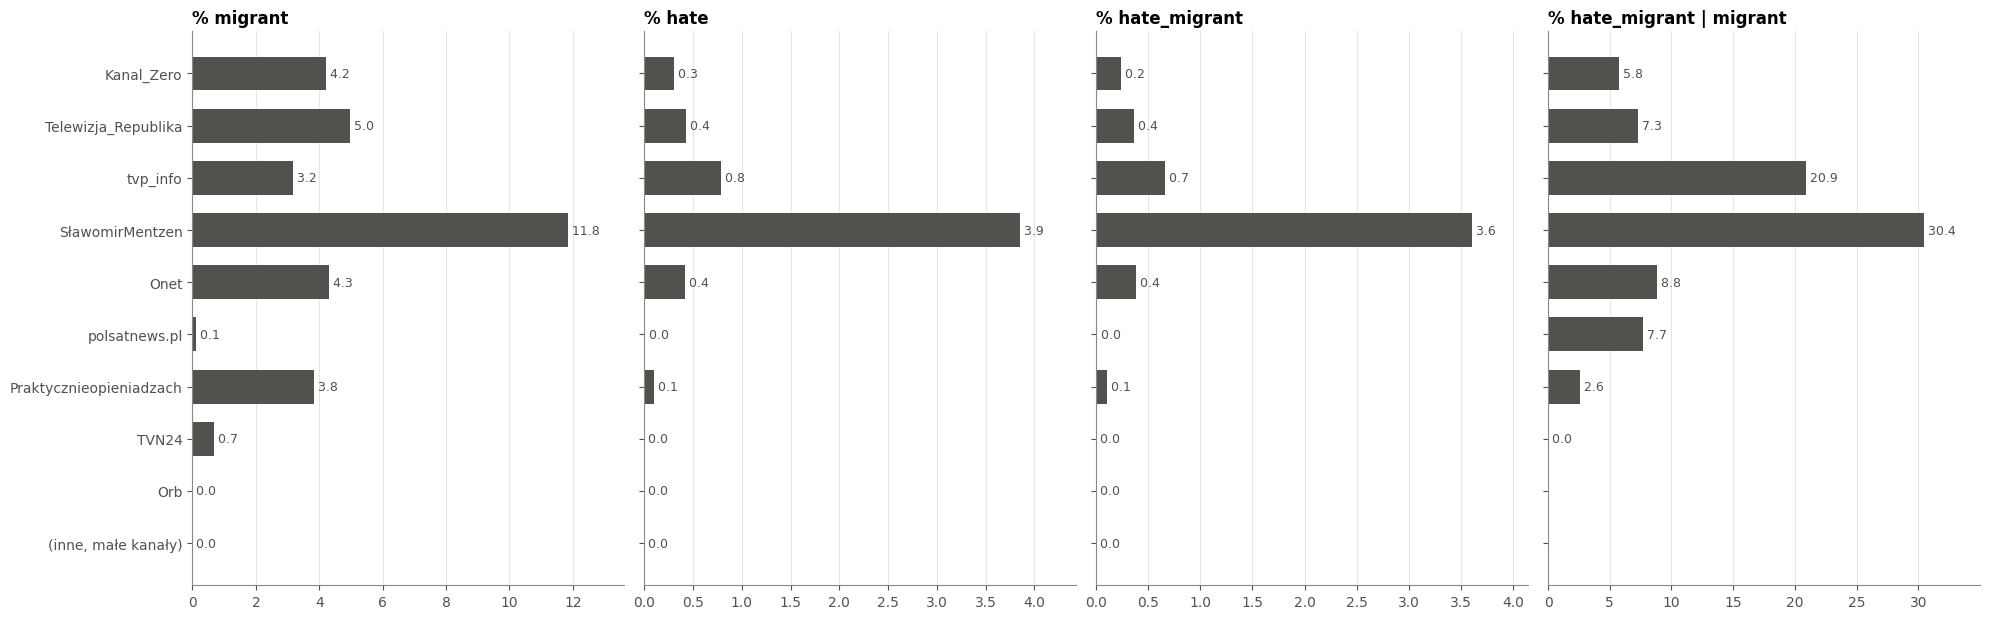

In [17]:
# komentarze bez przypisanego kanału (post_id spoza clean/posts.csv – zwykle 1–10% komentarzy wydarzenia)
# pomijamy w analizie kanałów, żeby nie pokazywać sztucznej grupy "(brak)"
df_kan = all_df[all_df["kanal"] != "(brak)"].copy()
print(f"analiza kanałów: {len(df_kan):,} komentarzy z przypisanym kanałem "
      f"({len(df_kan) / len(all_df):.1%} wszystkich)")
MIN_CHANNEL_N = 300      # mniejsze kanały -> grupa "(inne, małe kanały)"
MIN_CELL_N = 30          # min. liczba komentarzy w komórce kanał×wydarzenie / kanał×okres

ch_n = df_kan["kanal"].value_counts()
df_kan["kanal_gr"] = df_kan["kanal"].where(df_kan["kanal"].isin(ch_n[ch_n >= MIN_CHANNEL_N].index), "(inne, małe kanały)")
CHANNELS = df_kan["kanal_gr"].value_counts().index.tolist()
print(f"Kanałów: {df_kan['kanal'].nunique()}, po scaleniu małych: {len(CHANNELS)}")

mig = df_kan[df_kan["migrant"]]
share = df_kan.groupby(["okres", "kanal_gr"]).size().unstack("okres").reindex(CHANNELS).fillna(0)
share = 100 * share / share.sum()
ch = pd.DataFrame({
    "komentarzy": df_kan.groupby("kanal_gr").size(),
    "wydarzeń": df_kan.groupby("kanal_gr")["event"].nunique(),
    "postów": df_kan.groupby("kanal_gr")["post_id"].nunique(),
    "% migrant": 100 * df_kan.groupby("kanal_gr")["migrant"].mean(),
    "% hate": 100 * df_kan.groupby("kanal_gr")["hate"].mean(),
    "% hate_migrant": 100 * df_kan.groupby("kanal_gr")["hate_migrant"].mean(),
    "% hate_migrant | migrant": 100 * mig.groupby("kanal_gr")["hate_migrant"].mean(),
    "udział przed %": share["przed"], "udział po %": share["po"],
}).reindex(CHANNELS)
display(ch.round(2))

fig, axes = plt.subplots(1, 4, figsize=(20, 0.45 * len(CHANNELS) + 1.8), sharey=True)
for ax, col in zip(axes, ["% migrant", "% hate", "% hate_migrant", "% hate_migrant | migrant"]):
    v = ch[col][::-1]
    ax.barh(v.index, v.values, color=INK2, height=0.65)
    for yi, x in enumerate(v.values):
        ax.text(x, yi, f" {x:.1f}", va="center", color=INK2, fontsize=9)
    ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
    ax.margins(x=0.15)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [18]:
def channel_effect(d, col):
    pre, post = d.loc[d["okres"] == "przed", col], d.loc[d["okres"] == "po", col]
    n1, n2 = len(pre), len(post)
    out = {"n przed": n1, "n po": n2, "przed %": np.nan, "po %": np.nan, "różnica pp": np.nan,
           "OR": np.nan, "OR lo": np.nan, "OR hi": np.nan, "p": np.nan}
    if n1 < MIN_CELL_N or n2 < MIN_CELL_N:
        return out
    out.update({"przed %": 100 * pre.mean(), "po %": 100 * post.mean(), "różnica pp": 100 * (post.mean() - pre.mean())})
    if col in d and d[col].nunique() < 2:
        return out
    try:
        f = "y ~ po + C(event)" if d["event"].nunique() > 1 else "y ~ po"
        m = smf.logit(f, data=d.assign(y=d[col].astype(int))).fit(
            disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(d["thread"])[0]}, maxiter=200)
        b, se = m.params["po"], m.bse["po"]
        out.update({"OR": np.exp(b), "OR lo": np.exp(b - 1.96 * se), "OR hi": np.exp(b + 1.96 * se), "p": m.pvalues["po"]})
    except Exception as exc:                    # separacja / brak zbieżności w małym kanale
        print(f"  (pominięto model: {col}, {d['kanal_gr'].iloc[0]}: {type(exc).__name__})")
    return out


rows = []
for name, (col, cond) in LABEL_SETS.items():
    d0 = df_kan[df_kan[cond]] if cond else df_kan
    for c in CHANNELS:
        rows.append({"etykieta": name, "kanał": c, **channel_effect(d0[d0["kanal_gr"] == c], col)})
eff_ch = pd.DataFrame(rows)
eff_ch["p (Holm)"] = eff_ch.groupby("etykieta")["p"].transform(
    lambda s: pd.Series(multipletests(s.dropna(), method="holm")[1], index=s.dropna().index).reindex(s.index))
eff_ch["istotne"] = eff_ch["p (Holm)"] < ALPHA

for name in LABEL_SETS:
    print(f"\n=== {LABEL_NAMES[name]}: efekt wydarzenia (po vs przed) w kanale ===")
    display(fmt_p(eff_ch[eff_ch["etykieta"] == name].set_index("kanał").drop(columns="etykieta"), 3))

/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


...

,n przed,n po,przed %,po %,różnica pp,OR,OR lo,OR hi,p,p (Holm),istotne
kanał,,,,,,,,,,,
Kanal_Zero,75646,226888,0.087,0.295,0.208,2.040000e+00,0.911,4.566000e+00,0.0829,0.249,False
Telewizja_Republika,33221,107367,0.226,0.401,0.176,1.183000e+00,0.457,3.062000e+00,0.729,0.729,False
tvp_info,9411,32919,0.043,0.841,0.799,2.428000e+00,0.360,1.639300e+01,0.362,0.725,False
SławomirMentzen,7408,32199,0.148,4.401,4.252,3.283000e+00,2.594,4.156000e+00,4.78e-23,2.87e-22,True
Onet,3201,17278,0.000,0.451,0.451,1.239696e+07,NaN,NaN,nan,nan,False
polsatnews.pl,3036,10164,0.000,0.010,0.010,2.462852e+06,91107.131,6.657699e+07,2.16e-18,1.08e-17,True
Praktycznieopieniadzach,1859,7083,0.000,0.127,0.127,5.472000e+00,3.010,9.947000e+00,2.49e-08,9.96e-08,True
TVN24,666,2947,0.000,0.000,0.000,NaN,NaN,NaN,nan,nan,False
Orb,71,268,0.000,0.000,0.000,NaN,NaN,NaN,nan,nan,False



=== o migracji: efekt wydarzenia (po vs przed) w kanale ===


,n przed,n po,przed %,po %,różnica pp,OR,OR lo,OR hi,p,p (Holm),istotne
kanał,,,,,,,,,,,
Kanal_Zero,75646,226888,3.506,4.464,0.958,0.991,0.553,1.774,0.975,1,False
Telewizja_Republika,33221,107367,2.763,5.635,2.872,1.603,1.063,2.419,0.0245,0.196,False
tvp_info,9411,32919,2.061,3.493,1.432,1.016,0.554,1.865,0.958,1,False
SławomirMentzen,7408,32199,6.183,13.153,6.970,2.315,0.463,11.574,0.307,1,False
Onet,3201,17278,3.124,4.538,1.414,1.268,0.622,2.585,0.513,1,False
polsatnews.pl,3036,10164,0.066,0.108,0.042,1.925,0.232,15.953,0.544,1,False
Praktycznieopieniadzach,1859,7083,11.027,1.962,-9.065,0.243,0.056,1.049,0.0579,0.405,False
TVN24,666,2947,0.901,0.611,-0.290,0.383,0.107,1.375,0.141,0.846,False
Orb,71,268,0.000,0.000,0.000,NaN,NaN,NaN,nan,nan,False



=== hate wobec migrantów wśród komentarzy o migracji: efekt wydarzenia (po vs przed) w kanale ===


,n przed,n po,przed %,po %,różnica pp,OR,OR lo,OR hi,p,p (Holm),istotne
kanał,,,,,,,,,,,
Kanal_Zero,2652,10128,2.489,6.605,4.117,1.922,0.826,4.468,0.129,0.259,False
Telewizja_Republika,918,6050,8.170,7.124,-1.046,2.075,1.166,3.693,0.0131,0.0524,False
tvp_info,194,1150,2.062,24.087,22.025,2.270,1.163,4.434,0.0163,0.0524,False
SławomirMentzen,458,4235,2.402,33.459,31.058,0.918,0.619,1.361,0.67,0.67,False
Onet,100,784,0.000,9.949,9.949,4.752,NaN,NaN,nan,nan,False
polsatnews.pl,2,11,NaN,NaN,NaN,NaN,NaN,NaN,nan,nan,False
Praktycznieopieniadzach,205,139,0.000,6.475,6.475,42.090,9.504,186.410,8.41e-07,4.2e-06,True
TVN24,6,18,NaN,NaN,NaN,NaN,NaN,NaN,nan,nan,False
Orb,0,0,NaN,NaN,NaN,NaN,NaN,NaN,nan,nan,False


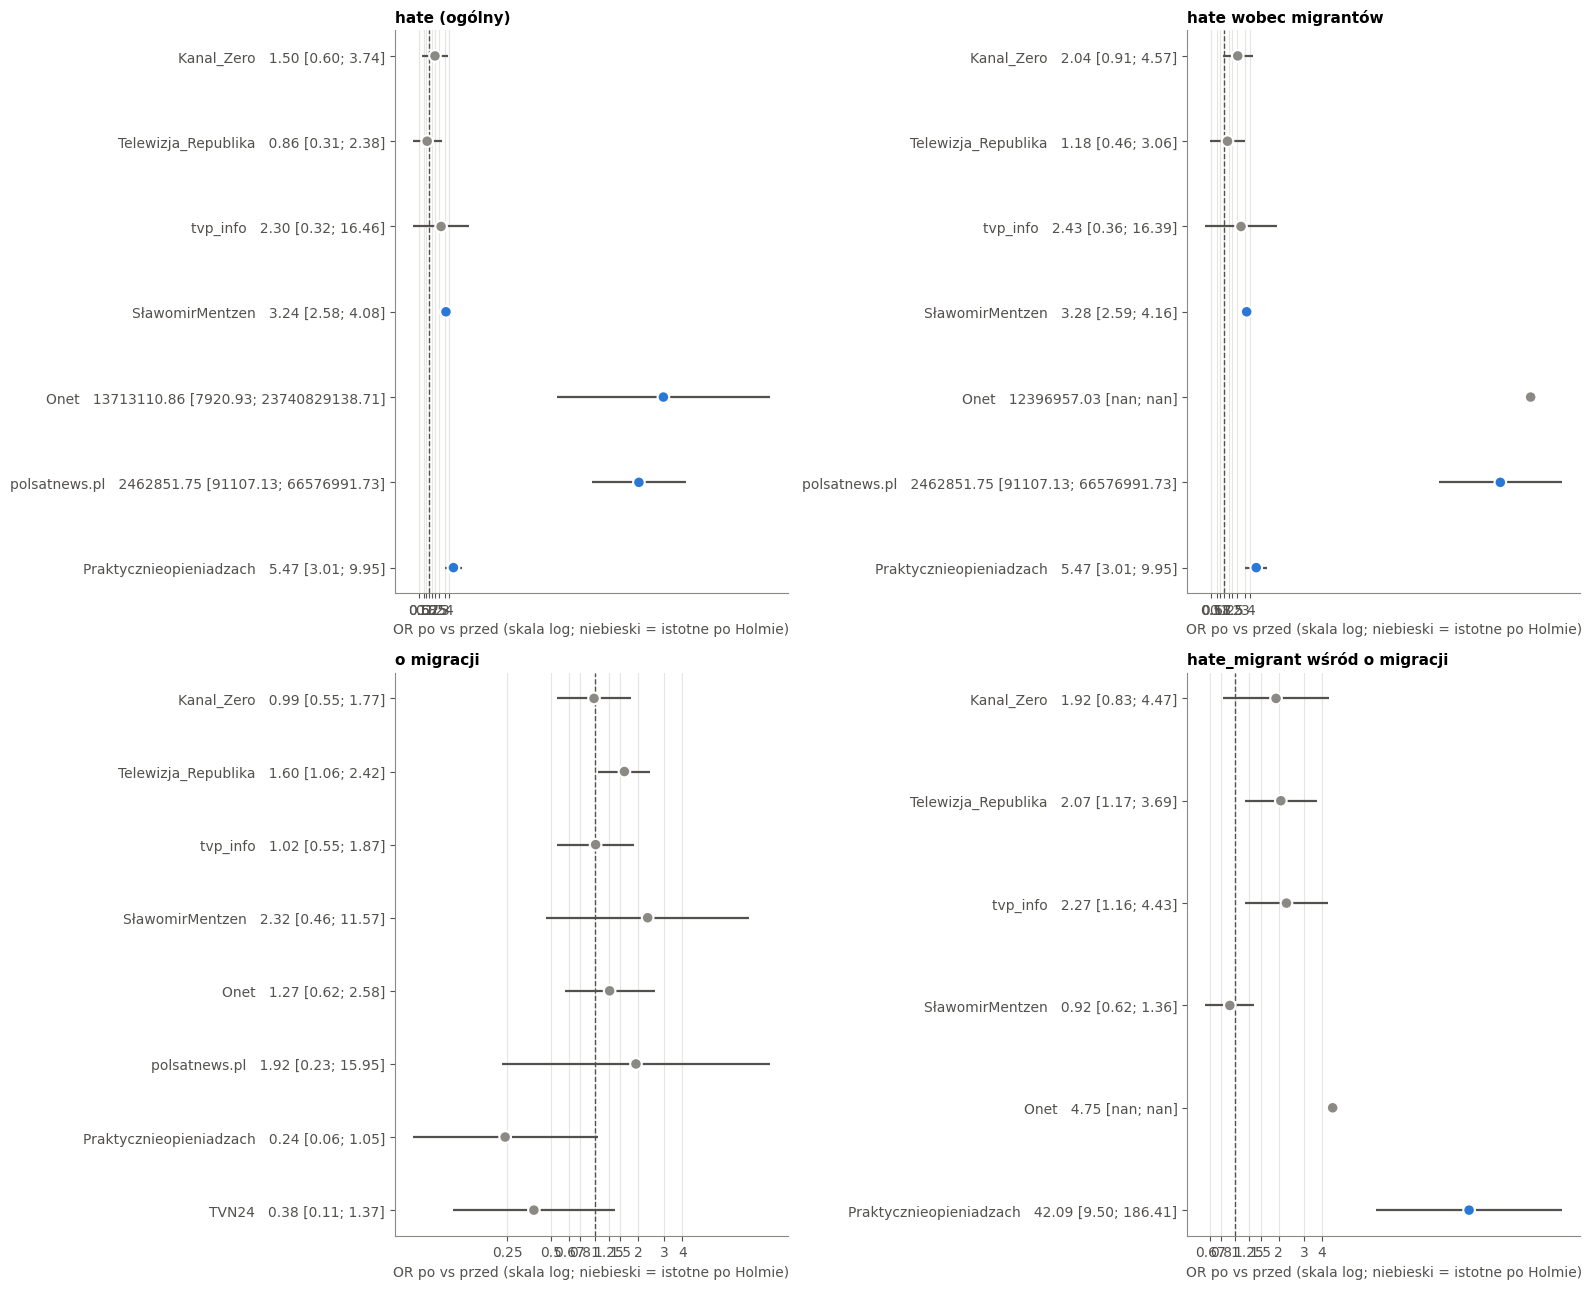

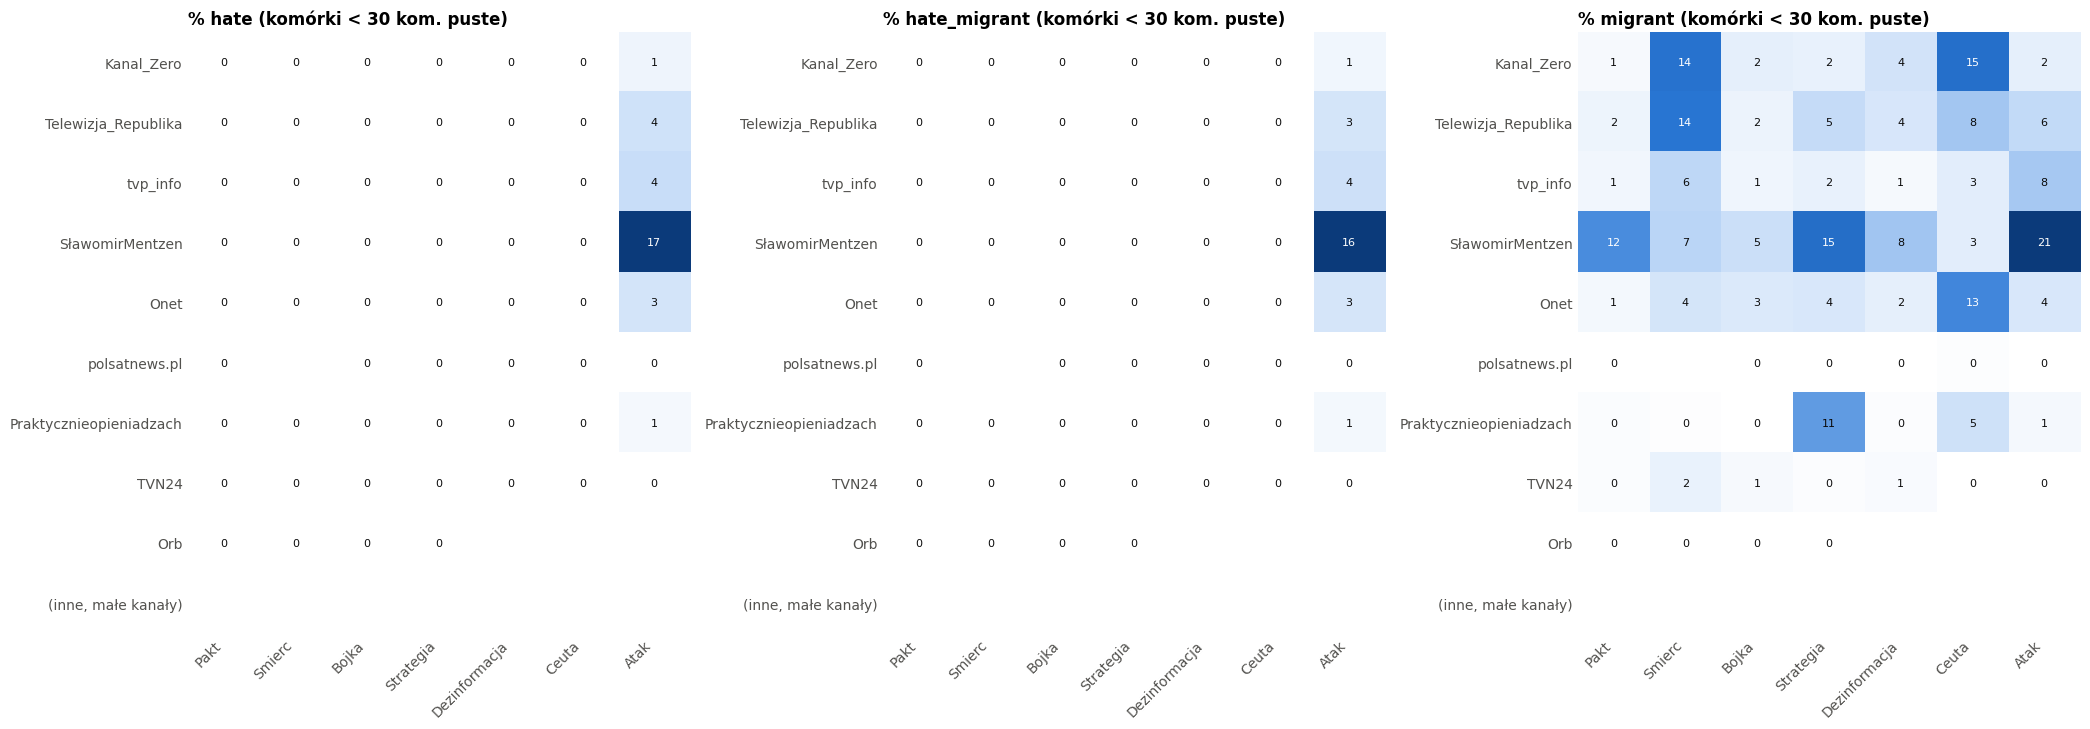

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(16, 2 * (0.45 * len(CHANNELS) + 2.0)))
for ax, name in zip(axes.flat, LABEL_SETS):
    e = eff_ch[(eff_ch["etykieta"] == name)].dropna(subset=["OR"]).set_index("kanał")
    y = np.arange(len(e))[::-1]
    if e.empty:
        ax.set_title(f"{LABEL_NAMES[name]} – brak danych"); continue
    ax.hlines(y, e["OR lo"], e["OR hi"], color=INK2, lw=1.6)
    ax.scatter(e["OR"], y, s=70, color=[COLORS["po"] if s else COLORS["przed"] for s in e["istotne"]],
               edgecolor="white", linewidth=1.5, zorder=3)
    ax.axvline(1, color=INK2, ls="--", lw=1)
    ax.set_xscale("log")
    ax.xaxis.set_minor_locator(mticker.NullLocator())
    ticks = [t for t in [0.25, 0.5, 0.67, 0.8, 1, 1.25, 1.5, 2, 3, 4] if e["OR lo"].min() * 0.9 <= t <= e["OR hi"].max() * 1.1]
    ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
    ax.set_yticks(y, [f"{k}   {o:.2f} [{lo:.2f}; {hi:.2f}]" for k, o, lo, hi in zip(e.index, e["OR"], e["OR lo"], e["OR hi"])])
    ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
    ax.set_xlabel("OR po vs przed (skala log; niebieski = istotne po Holmie)")
    ax.set_title(LABEL_NAMES[name] if len(LABEL_NAMES[name]) < 30 else "hate_migrant wśród o migracji", fontsize=11)
plt.tight_layout()
plt.show()

# mapy cieplne: kanał × wydarzenie
fig, axes = plt.subplots(1, len(LABELS), figsize=(7 * len(LABELS), 0.5 * len(CHANNELS) + 2.4))
for ax, lab in zip(axes, LABELS):
    g = df_kan.groupby(["kanal_gr", "event"])[lab].agg(["mean", "size"])
    tab = (100 * g["mean"].where(g["size"] >= MIN_CELL_N)).unstack("event").reindex(index=CHANNELS, columns=EVENT_ORDER)
    ax.imshow(tab.values, cmap=BLUES, aspect="auto", vmin=0)
    for (i, j), v in np.ndenumerate(tab.values):
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if v > 0.55 * np.nanmax(tab.values) else INK)
    ax.set_xticks(range(tab.shape[1]), [e.split("_")[0] for e in tab.columns], rotation=45, ha="right")
    ax.set_yticks(range(len(tab)), tab.index)
    ax.grid(False); ax.tick_params(length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_title(f"% {lab} (komórki < {MIN_CELL_N} kom. puste)")
plt.tight_layout()
plt.show()

In [20]:
def wald_terms(d, col, formula, prefix):
    m = smf.logit(formula, data=d.assign(y=d[col].astype(int))).fit(
        disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(d["thread"])[0]}, maxiter=200)
    idx = [i for i, n in enumerate(m.params.index) if n.startswith(prefix)]
    if not idx:
        return np.nan
    return float(m.wald_test(np.eye(len(m.params))[idx], scalar=True).pvalue)


# tylko kanały z danymi zarówno przed, jak i po
ok = [c for c in CHANNELS if df_kan.loc[df_kan["kanal_gr"] == c, "okres"].nunique() == 2]
dch = df_kan[df_kan["kanal_gr"].isin(ok)]
test_ch = []
for name, (col, cond) in LABEL_SETS.items():
    d = dch[dch[cond]] if cond else dch
    row = {"etykieta": name}
    for key, f, pre in [("p różnica poziomu kanałów", "y ~ C(event) + po + C(kanal_gr)", "C(kanal_gr)"),
                        ("p różnica efektu wydarzenia między kanałami", "y ~ C(event) + C(kanal_gr) + po + po:C(kanal_gr)", "po:C(kanal_gr)")]:
        try:
            row[key] = wald_terms(d, col, f, pre)
        except Exception as exc:
            row[key] = np.nan
            print(f"  (test pominięty: {name}, {type(exc).__name__})")
    test_ch.append(row)
display(fmt_p(pd.DataFrame(test_ch).set_index("etykieta"), 3))
print("Poziom: czy kanały różnią się odsetkiem etykiety (przy kontroli wydarzenia). "
      "Efekt: czy wzrost/spadek po wydarzeniu zależy od kanału.")

# słowa charakterystyczne dla hejtu w kanale (vs hejt w pozostałych kanałach)
hm_ch = df_kan[df_kan["hate_migrant"]]
counts_ch = {c: count_words(hm_ch.loc[hm_ch["kanal_gr"] == c, "text"]) for c in CHANNELS}
n_hate = hm_ch["kanal_gr"].value_counts()
total_ch = sum(counts_ch.values(), Counter())
words_ch = {}
for c in CHANNELS:
    if n_hate.get(c, 0) < 50:
        continue
    r = log_odds(counts_ch[c], total_ch - counts_ch[c], total_ch).head(TOP_N_WORDS)
    words_ch[f"{c} (n={n_hate[c]})"] = [f"{w} (z={z:.1f})" for w, z in zip(r["słowo"], r["z"])]
print("\nSłowa charakterystyczne dla hejtu wobec migrantów w kanale (vs pozostałe kanały):")
if words_ch:
    display(pd.DataFrame({k: v + [""] * (TOP_N_WORDS - len(v)) for k, v in words_ch.items()}, index=range(1, TOP_N_WORDS + 1)))
else:
    print("(za mało komentarzy hate_migrant w kanałach)")

/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


...

/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,p różnica poziomu kanałów,p różnica efektu wydarzenia między kanałami
etykieta,,
hate,5.09e-269,1.74e-42
hate_migrant,2.03e-273,6.89e-68
migrant,7.14e-247,0.0383
hate_migrant | migrant,1.52e-160,3.42e-19


Poziom: czy kanały różnią się odsetkiem etykiety (przy kontroli wydarzenia). Efekt: czy wzrost/spadek po wydarzeniu zależy od kanału.

Słowa charakterystyczne dla hejtu wobec migrantów w kanale (vs pozostałe kanały):


,Kanal_Zero (n=735),Telewizja_Republika (n=506),tvp_info (n=281),SławomirMentzen (n=1428),Onet (n=78)
1,bojke (z=4.2),hiszpanie (z=3.2),seweryn (z=4.5),ukraińców (z=5.9),płacz (z=3.2)
2,afd (z=3.6),dzicz (z=2.8),stary (z=3.2),ukrainiec (z=4.9),tamten (z=3.2)
3,azyl (z=2.9),zbiry (z=2.8),obowiązki (z=2.8),ukraińcy (z=4.4),wołynia (z=3.2)
4,strzelać (z=2.8),upadliny (z=2.6),polowanie (z=2.6),polaka (z=3.9),brzucha (z=3.2)
5,ukrócić (z=2.4),pozwał (z=2.4),seweryna (z=2.4),polsce (z=3.9),zadawanie (z=3.0)
6,arleta (z=2.4),zbrodniarzy (z=2.3),dziad (z=2.2),dyj (z=3.8),wkładanie (z=3.0)
7,strzela (z=2.4),rakieta (z=2.3),walczyć (z=1.9),polacy (z=3.8),rozcinanie (z=2.8)
8,nielegalnie (z=2.3),dzikusy (z=2.2),ludzi (z=1.8),mentzen (z=3.7),głowy (z=2.6)
9,granice (z=2.3),daja (z=2.2),deportować (z=1.7),policja (z=3.5),pośród (z=2.4)
10,wyjadą (z=2.2),europy (z=2.1),mężczyzn (z=1.7),polskie (z=3.2),kresowych (z=2.4)


## 9. Podsumowanie (generowane automatycznie)

In [21]:
for name, r in pooled.iterrows():
    e = eff[eff["etykieta"] == name].set_index("event")["różnica pp"]
    verdict = "ISTOTNY wspólny wzrost" if r["wspólny wzrost istotny (meta)"] else "brak istotnego wspólnego efektu"
    i2 = "–" if np.isnan(r["I²"]) else f"{r['I²']:.0%}"
    print(f"{LABEL_NAMES[name]}:\n"
          f"  wzrost w {r['wzrost w']} wydarzeń (istotny w {r['istotny wzrost w']}), średnio {r['średnia zmiana pp']:+.2f} pp\n"
          f"  metaanaliza: OR = {r['OR łączny (meta)']:.2f} [{r['OR lo']:.2f}; {r['OR hi']:.2f}], "
          f"p (Holm) = {r['p meta (Holm)']:.3g} -> {verdict}\n"
          f"  różnice między wydarzeniami: I² = {i2}\n"
          f"  okna bez nakładania: wzrost w {r['wzrost w (bez nakładania)']}, OR = {r['OR meta bez nakładania']:.2f} "
          f"[{r['OR lo bez nakładania']:.2f}; {r['OR hi bez nakładania']:.2f}], p = {r['p meta bez nakładania']:.3g}\n"
          f"  największa zmiana: {e.idxmax()} ({e.max():+.1f} pp), najmniejsza: {e.idxmin()} ({e.min():+.1f} pp)\n")
if skipped:
    print("Pominięte wydarzenia:", ", ".join(f"{k} ({v})" for k, v in skipped.items()))

hate (ogólny):
  wzrost w 1/7 wydarzeń (istotny w 0/7), średnio +0.26 pp
  metaanaliza: OR = 0.23 [0.08; 0.64], p (Holm) = 0.0498 -> brak istotnego wspólnego efektu
  różnice między wydarzeniami: I² = 87%
  okna bez nakładania: wzrost w 1/7, OR = 0.31 [0.16; 0.63], p = 0.00666
  największa zmiana: Atak_Kamienna_Gora (+1.8 pp), najmniejsza: Pakt_Azyl_PE (+0.0 pp)

hate wobec migrantów:
  wzrost w 1/7 wydarzeń (istotny w 1/7), średnio +0.29 pp
  metaanaliza: OR = 0.24 [0.07; 0.76], p (Holm) = 0.0699 -> brak istotnego wspólnego efektu
  różnice między wydarzeniami: I² = 90%
  okna bez nakładania: wzrost w 1/7, OR = 0.33 [0.14; 0.75], p = 0.0163
  największa zmiana: Atak_Kamienna_Gora (+2.0 pp), najmniejsza: Pakt_Azyl_PE (+0.0 pp)

o migracji:
  wzrost w 5/7 wydarzeń (istotny w 2/7), średnio +1.80 pp
  metaanaliza: OR = 1.75 [0.87; 3.55], p (Holm) = 0.0992 -> brak istotnego wspólnego efektu
  różnice między wydarzeniami: I² = 71%
  okna bez nakładania: wzrost w 4/7, OR = 1.39 [0.59; 3.26],